In [1]:
!pip install pandas
!pip install streamlit scikit-learn pandas numpy matplotlib joblib


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.4/10.4 MB 30.5 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.4/11.4 MB 69.8 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2/2 [streamlit]


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [3]:
df =pd.read_csv('Student_Performance.csv')


In [4]:
df.head(3)

,student_id,age,gender,school_type,parent_education,study_hours,attendance_percentage,internet_access,travel_time,extra_activities,study_method,math_score,science_score,english_score,overall_score,final_grade
0,1,14,male,public,post graduate,3.1,84.3,yes,<15 min,yes,notes,42.7,55.4,57.0,53.1,e
1,2,18,female,public,graduate,3.7,87.8,yes,>60 min,no,textbook,57.6,68.8,64.8,61.3,d
2,3,17,female,private,post graduate,7.9,65.5,no,<15 min,no,notes,84.8,95.0,79.2,89.6,b


In [5]:
df.columns.unique()

Index(['student_id', 'age', 'gender', 'school_type', 'parent_education',
       'study_hours', 'attendance_percentage', 'internet_access',
       'travel_time', 'extra_activities', 'study_method', 'math_score',
       'science_score', 'english_score', 'overall_score', 'final_grade'],
      dtype='object')

In [6]:
df.duplicated().value_counts()

,count
False,15000
True,10000


In [7]:
print(f"There are total  {df.duplicated().sum()} duplicate rows in the dataset.")

There are total  10000 duplicate rows in the dataset.


In [8]:
df.drop_duplicates(inplace=True)


In [9]:
df.shape

(15000, 16)

In [10]:
df.isnull().sum()

,0
student_id,0
age,0
gender,0
school_type,0
parent_education,0
study_hours,0
attendance_percentage,0
internet_access,0
travel_time,0
extra_activities,0


In [11]:
for column in df.columns:
    print(f"Unique values in column '{column}':")
    print(len(df[column].unique()))
    print()

Unique values in column 'student_id':
15000

Unique values in column 'age':
6

Unique values in column 'gender':
3

Unique values in column 'school_type':
2

Unique values in column 'parent_education':
6

Unique values in column 'study_hours':
76

Unique values in column 'attendance_percentage':
501

Unique values in column 'internet_access':
2

Unique values in column 'travel_time':
4

Unique values in column 'extra_activities':
2

Unique values in column 'study_method':
6

Unique values in column 'math_score':
906

Unique values in column 'science_score':
907

Unique values in column 'english_score':
904

Unique values in column 'overall_score':
808

Unique values in column 'final_grade':
6



In [12]:
numeric_features = [column for column in df.columns if df[column].dtype != 'object']
categorical_features = [column for column in df.columns if df[column].dtype == 'object']

print("Numeric features:", numeric_features)
print("Catagorical features:", categorical_features)

Numeric features: ['student_id', 'age', 'study_hours', 'attendance_percentage', 'math_score', 'science_score', 'english_score', 'overall_score']
Catagorical features: ['gender', 'school_type', 'parent_education', 'internet_access', 'travel_time', 'extra_activities', 'study_method', 'final_grade']


In [13]:
for col in categorical_features:
    print(f"Unique values in column '{col}':")
    print(df[col].unique())
    print()

Unique values in column 'gender':
['male' 'female' 'other']

Unique values in column 'school_type':
['public' 'private']

Unique values in column 'parent_education':
['post graduate' 'graduate' 'high school' 'no formal' 'diploma' 'phd']

Unique values in column 'internet_access':
['yes' 'no']

Unique values in column 'travel_time':
['<15 min' '>60 min' '15-30 min' '30-60 min']

Unique values in column 'extra_activities':
['yes' 'no']

Unique values in column 'study_method':
['notes' 'textbook' 'group study' 'coaching' 'mixed' 'online videos']

Unique values in column 'final_grade':
['e' 'd' 'b' 'f' 'c' 'a']



In [14]:
#
for column in df.columns:
    if column == 'Nan':
        print(f"Unique values in column '{column}':")
        print(df[column].unique())
        print()

In [15]:
import numpy as np
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.model_selection import train_test_split


In [16]:
df['final_grade']=df['final_grade'].map({'a':6,'b':5,'c':4,'d':3,'e':2,'f':1})

In [17]:
ohe=OneHotEncoder()
oe=OrdinalEncoder()

In [18]:
X = df.drop(columns=['student_id', 'final_grade'])

y = df['final_grade']


In [19]:
X.shape,y.shape

((15000, 14), (15000,))

In [20]:
X['travel_time']=X['travel_time'].map({'<15 min':4,'15-30 min':3,'30-60 min':2,'> 60 min':1})
X['parent_education']=X['parent_education'].map({'no formal':0,'high school':1,'diploma':3,'graduate':4,'post graduate':5,'phd':6})
ohe_encoded = ohe.fit_transform(X[['gender', 'internet_access', 'school_type', 'study_method','extra_activities']])



In [21]:
X.drop(columns=['gender', 'internet_access', 'school_type', 'study_method','extra_activities'], inplace=True)

In [22]:
ohe = OneHotEncoder(drop='first', sparse_output=False)
mapped_df = df.copy()
mapped_df['travel_time'] = mapped_df['travel_time'].map({'<15 min': 4, '15-30 min': 3, '30-60 min': 2, '> 60 min': 1, '>60 min': 1})
mapped_df['parent_education'] = mapped_df['parent_education'].map({'no formal': 0, 'high school': 1, 'diploma': 3, 'graduate': 4, 'post graduate': 5, 'phd': 6})



In [23]:
categorical_cols = ['gender', 'internet_access', 'school_type', 'study_method', 'extra_activities']
ohe_encoded_array = ohe.fit_transform(mapped_df[categorical_cols])

ohe_encoded_df = pd.DataFrame(
    ohe_encoded_array,
    columns=ohe.get_feature_names_out(categorical_cols),
    index=mapped_df.index
)


numeric_cols = ['age', 'parent_education', 'study_hours', 'attendance_percentage', 'travel_time', 'math_score', 'science_score', 'english_score', 'overall_score']


X_encoded = pd.concat([mapped_df[numeric_cols], ohe_encoded_df], axis=1)

X_train, X_test, y_train, y_test = train_test_split(X_encoded, y, test_size=0.2, random_state=42)


imputer = SimpleImputer(strategy='median')
X_train_encoded_df = pd.DataFrame(imputer.fit_transform(X_train), columns=X_train.columns, index=X_train.index)
X_test_encoded_df = pd.DataFrame(imputer.transform(X_test), columns=X_test.columns, index=X_test.index)


display(X_train_encoded_df.head(3))

,age,parent_education,study_hours,attendance_percentage,travel_time,math_score,science_score,english_score,overall_score,gender_male,gender_other,internet_access_yes,school_type_public,study_method_group study,study_method_mixed,study_method_notes,study_method_online videos,study_method_textbook,extra_activities_yes
9839,16.0,1.0,1.6,73.5,4.0,59.1,57.7,53.0,44.2,1.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0
9680,14.0,3.0,7.6,89.6,4.0,100.0,86.5,100.0,100.0,0.0,1.0,1.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0
7093,16.0,0.0,0.8,60.6,1.0,20.9,39.8,41.2,25.0,0.0,1.0,1.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0


In [24]:

print("Shape of processed training features:", X_train_encoded_df.shape)
print("Missing values remaining in features:", X_train_encoded_df.isnull().sum().sum())
print("\nDistribution of the target variable (y_train):")
print(y_train.value_counts().sort_index())

display(X_train_encoded_df.head())

Shape of processed training features: (12000, 19)
Missing values remaining in features: 0

Distribution of the target variable (y_train):
final_grade
1    1408
2    2708
3    3049
4    2945
5    1324
6     566
Name: count, dtype: int64


,age,parent_education,study_hours,attendance_percentage,travel_time,math_score,science_score,english_score,overall_score,gender_male,gender_other,internet_access_yes,school_type_public,study_method_group study,study_method_mixed,study_method_notes,study_method_online videos,study_method_textbook,extra_activities_yes
9839,16.0,1.0,1.6,73.5,4.0,59.1,57.7,53.0,44.2,1.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0
9680,14.0,3.0,7.6,89.6,4.0,100.0,86.5,100.0,100.0,0.0,1.0,1.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0
7093,16.0,0.0,0.8,60.6,1.0,20.9,39.8,41.2,25.0,0.0,1.0,1.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0
11293,17.0,4.0,6.2,63.3,2.0,64.2,68.1,71.4,66.9,0.0,1.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0
820,14.0,0.0,7.5,89.9,1.0,91.5,88.9,89.1,100.0,0.0,1.0,1.0,1.0,1.0,0.0,0.0,0.0,0.0,1.0


In [25]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [26]:
pd.DataFrame(X_train)

,age,parent_education,study_hours,attendance_percentage,travel_time,math_score,science_score,english_score,overall_score
9839,16,1,1.6,73.5,4.0,59.1,57.7,53.0,44.2
9680,14,3,7.6,89.6,4.0,100.0,86.5,100.0,100.0
7093,16,0,0.8,60.6,NaN,20.9,39.8,41.2,25.0
11293,17,4,6.2,63.3,2.0,64.2,68.1,71.4,66.9
820,14,0,7.5,89.9,NaN,91.5,88.9,89.1,100.0
...,...,...,...,...,...,...,...,...,...
5191,19,5,4.9,67.6,4.0,78.5,83.9,63.5,69.0
13418,16,4,0.7,51.4,3.0,59.4,23.5,24.6,30.3
5390,15,6,1.9,62.4,2.0,36.0,32.7,28.6,40.0
860,19,5,0.8,98.3,3.0,54.3,45.4,51.5,53.9


In [27]:
X.info()

<class 'pandas.core.frame.DataFrame'>
Index: 15000 entries, 0 to 14999
Data columns (total 9 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   age                    15000 non-null  int64  
 1   parent_education       15000 non-null  int64  
 2   study_hours            15000 non-null  float64
 3   attendance_percentage  15000 non-null  float64
 4   travel_time            11284 non-null  float64
 5   math_score             15000 non-null  float64
 6   science_score          15000 non-null  float64
 7   english_score          15000 non-null  float64
 8   overall_score          15000 non-null  float64
dtypes: float64(7), int64(2)
memory usage: 1.1 MB


In [28]:


X_train_final = X_train_encoded_df
X_test_final = X_test_encoded_df

print("Train features shape:", X_train_final.shape)
print("Test features shape:", X_test_final.shape)
display(X_train_final.head(3))

Train features shape: (12000, 19)
Test features shape: (3000, 19)


,age,parent_education,study_hours,attendance_percentage,travel_time,math_score,science_score,english_score,overall_score,gender_male,gender_other,internet_access_yes,school_type_public,study_method_group study,study_method_mixed,study_method_notes,study_method_online videos,study_method_textbook,extra_activities_yes
9839,16.0,1.0,1.6,73.5,4.0,59.1,57.7,53.0,44.2,1.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0
9680,14.0,3.0,7.6,89.6,4.0,100.0,86.5,100.0,100.0,0.0,1.0,1.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0
7093,16.0,0.0,0.8,60.6,1.0,20.9,39.8,41.2,25.0,0.0,1.0,1.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0


In [29]:

mapped_df = df.copy()
mapped_df['travel_time'] = mapped_df['travel_time'].map({'<15 min': 4, '15-30 min': 3, '30-60 min': 2, '> 60 min': 1, '>60 min': 1})
mapped_df['parent_education'] = mapped_df['parent_education'].map({'no formal': 0, 'high school': 1, 'diploma': 3, 'graduate': 4, 'post graduate': 5, 'phd': 6})


nominal_cols = ['gender', 'internet_access', 'school_type', 'study_method', 'extra_activities']
numeric_cols = ['age', 'parent_education', 'study_hours', 'attendance_percentage', 'travel_time', 'math_score', 'science_score', 'english_score', 'overall_score']


X_raw = mapped_df[nominal_cols + numeric_cols]
y_raw = y


X_train, X_test, y_train, y_test = train_test_split(X_raw, y_raw, test_size=0.2, random_state=42)


preprocessor = ColumnTransformer([
    ('onehot', OneHotEncoder(), nominal_cols),
    ('numeric', SimpleImputer(strategy='median'), numeric_cols)
], remainder='drop')


X_train_processed = preprocessor.fit_transform(X_train)
X_test_processed = preprocessor.transform(X_test)


all_feature_names = preprocessor.get_feature_names_out()


X_train_final = pd.DataFrame(X_train_processed, columns=all_feature_names, index=X_train.index)
X_test_final = pd.DataFrame(X_test_processed, columns=all_feature_names, index=X_test.index)


print("Perfectly extracted features via get_feature_names_out():")
print(list(X_train_final.columns))

display(X_train_final.head(3))

Perfectly extracted features via get_feature_names_out():
['onehot__gender_female', 'onehot__gender_male', 'onehot__gender_other', 'onehot__internet_access_no', 'onehot__internet_access_yes', 'onehot__school_type_private', 'onehot__school_type_public', 'onehot__study_method_coaching', 'onehot__study_method_group study', 'onehot__study_method_mixed', 'onehot__study_method_notes', 'onehot__study_method_online videos', 'onehot__study_method_textbook', 'onehot__extra_activities_no', 'onehot__extra_activities_yes', 'numeric__age', 'numeric__parent_education', 'numeric__study_hours', 'numeric__attendance_percentage', 'numeric__travel_time', 'numeric__math_score', 'numeric__science_score', 'numeric__english_score', 'numeric__overall_score']


,onehot__gender_female,onehot__gender_male,onehot__gender_other,onehot__internet_access_no,onehot__internet_access_yes,onehot__school_type_private,onehot__school_type_public,onehot__study_method_coaching,onehot__study_method_group study,onehot__study_method_mixed,...,onehot__extra_activities_yes,numeric__age,numeric__parent_education,numeric__study_hours,numeric__attendance_percentage,numeric__travel_time,numeric__math_score,numeric__science_score,numeric__english_score,numeric__overall_score
9839,0.0,1.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0,0.0,...,0.0,16.0,1.0,1.6,73.5,4.0,59.1,57.7,53.0,44.2
9680,0.0,0.0,1.0,0.0,1.0,0.0,1.0,0.0,0.0,1.0,...,0.0,14.0,3.0,7.6,89.6,4.0,100.0,86.5,100.0,100.0
7093,0.0,0.0,1.0,0.0,1.0,0.0,1.0,0.0,0.0,1.0,...,0.0,16.0,0.0,0.8,60.6,1.0,20.9,39.8,41.2,25.0


In [30]:
X_test_final


,onehot__gender_female,onehot__gender_male,onehot__gender_other,onehot__internet_access_no,onehot__internet_access_yes,onehot__school_type_private,onehot__school_type_public,onehot__study_method_coaching,onehot__study_method_group study,onehot__study_method_mixed,...,onehot__extra_activities_yes,numeric__age,numeric__parent_education,numeric__study_hours,numeric__attendance_percentage,numeric__travel_time,numeric__math_score,numeric__science_score,numeric__english_score,numeric__overall_score
11499,0.0,1.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0,0.0,...,0.0,19.0,0.0,6.0,55.0,3.0,63.5,66.8,58.4,68.2
6475,1.0,0.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0,1.0,...,0.0,15.0,3.0,0.7,71.1,1.0,27.6,30.3,28.1,35.6
13167,1.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,...,1.0,15.0,6.0,2.2,63.9,2.0,54.7,45.1,55.4,43.7
862,0.0,1.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0,0.0,...,0.0,14.0,6.0,3.7,89.0,4.0,73.9,70.7,82.9,72.8
5970,0.0,0.0,1.0,0.0,1.0,1.0,0.0,1.0,0.0,0.0,...,1.0,18.0,1.0,7.3,50.2,4.0,73.7,71.2,84.1,80.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
6216,0.0,0.0,1.0,0.0,1.0,1.0,0.0,0.0,1.0,0.0,...,1.0,16.0,4.0,5.1,68.0,4.0,48.8,58.2,61.7,58.0
3585,0.0,0.0,1.0,1.0,0.0,0.0,1.0,0.0,1.0,0.0,...,1.0,15.0,1.0,2.0,59.3,1.0,53.8,36.0,50.3,39.7
10023,0.0,1.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0,0.0,...,1.0,17.0,4.0,1.1,92.2,2.0,38.7,58.6,43.1,49.1
14044,1.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,1.0,...,0.0,18.0,3.0,7.6,74.2,4.0,94.2,92.8,87.4,96.3


In [31]:
y_train.value_counts()

,count
final_grade,
3,3049
4,2945
2,2708
1,1408
5,1324
6,566


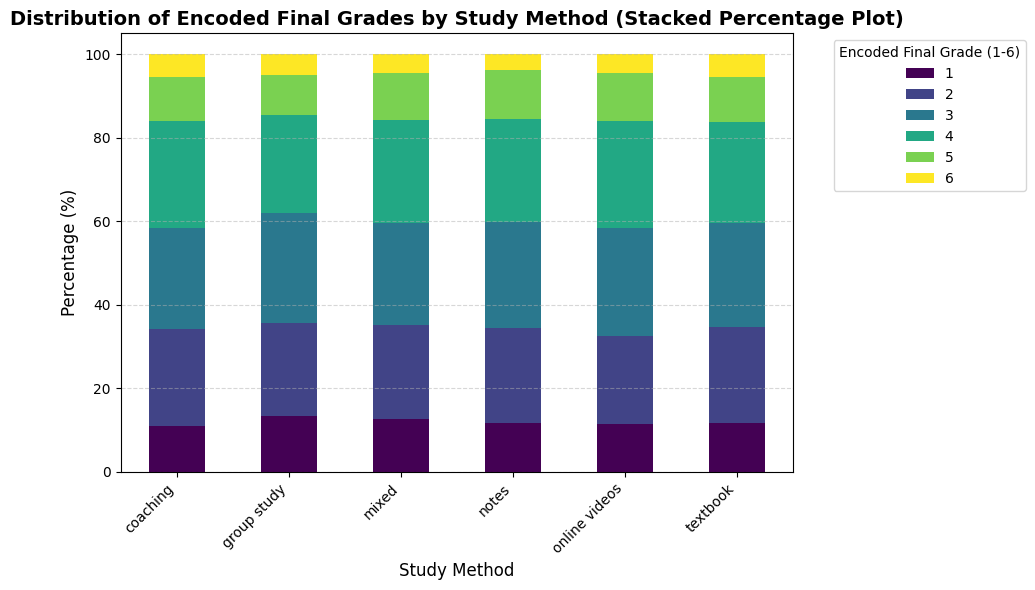

In [32]:

contingency_table = pd.crosstab(df['study_method'], y)

contingency_pct = contingency_table.div(contingency_table.sum(axis=1), axis=0) * 100

fig, ax = plt.subplots(figsize=(10, 6))
contingency_pct.plot(kind='bar', stacked=True, colormap='viridis', ax=ax)

plt.title('Distribution of Encoded Final Grades by Study Method (Stacked Percentage Plot)', fontsize=14, fontweight='bold')
plt.xlabel('Study Method', fontsize=12)
plt.ylabel('Percentage (%)', fontsize=12)
plt.xticks(rotation=45, ha='right')
plt.legend(title='Encoded Final Grade (1-6)', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

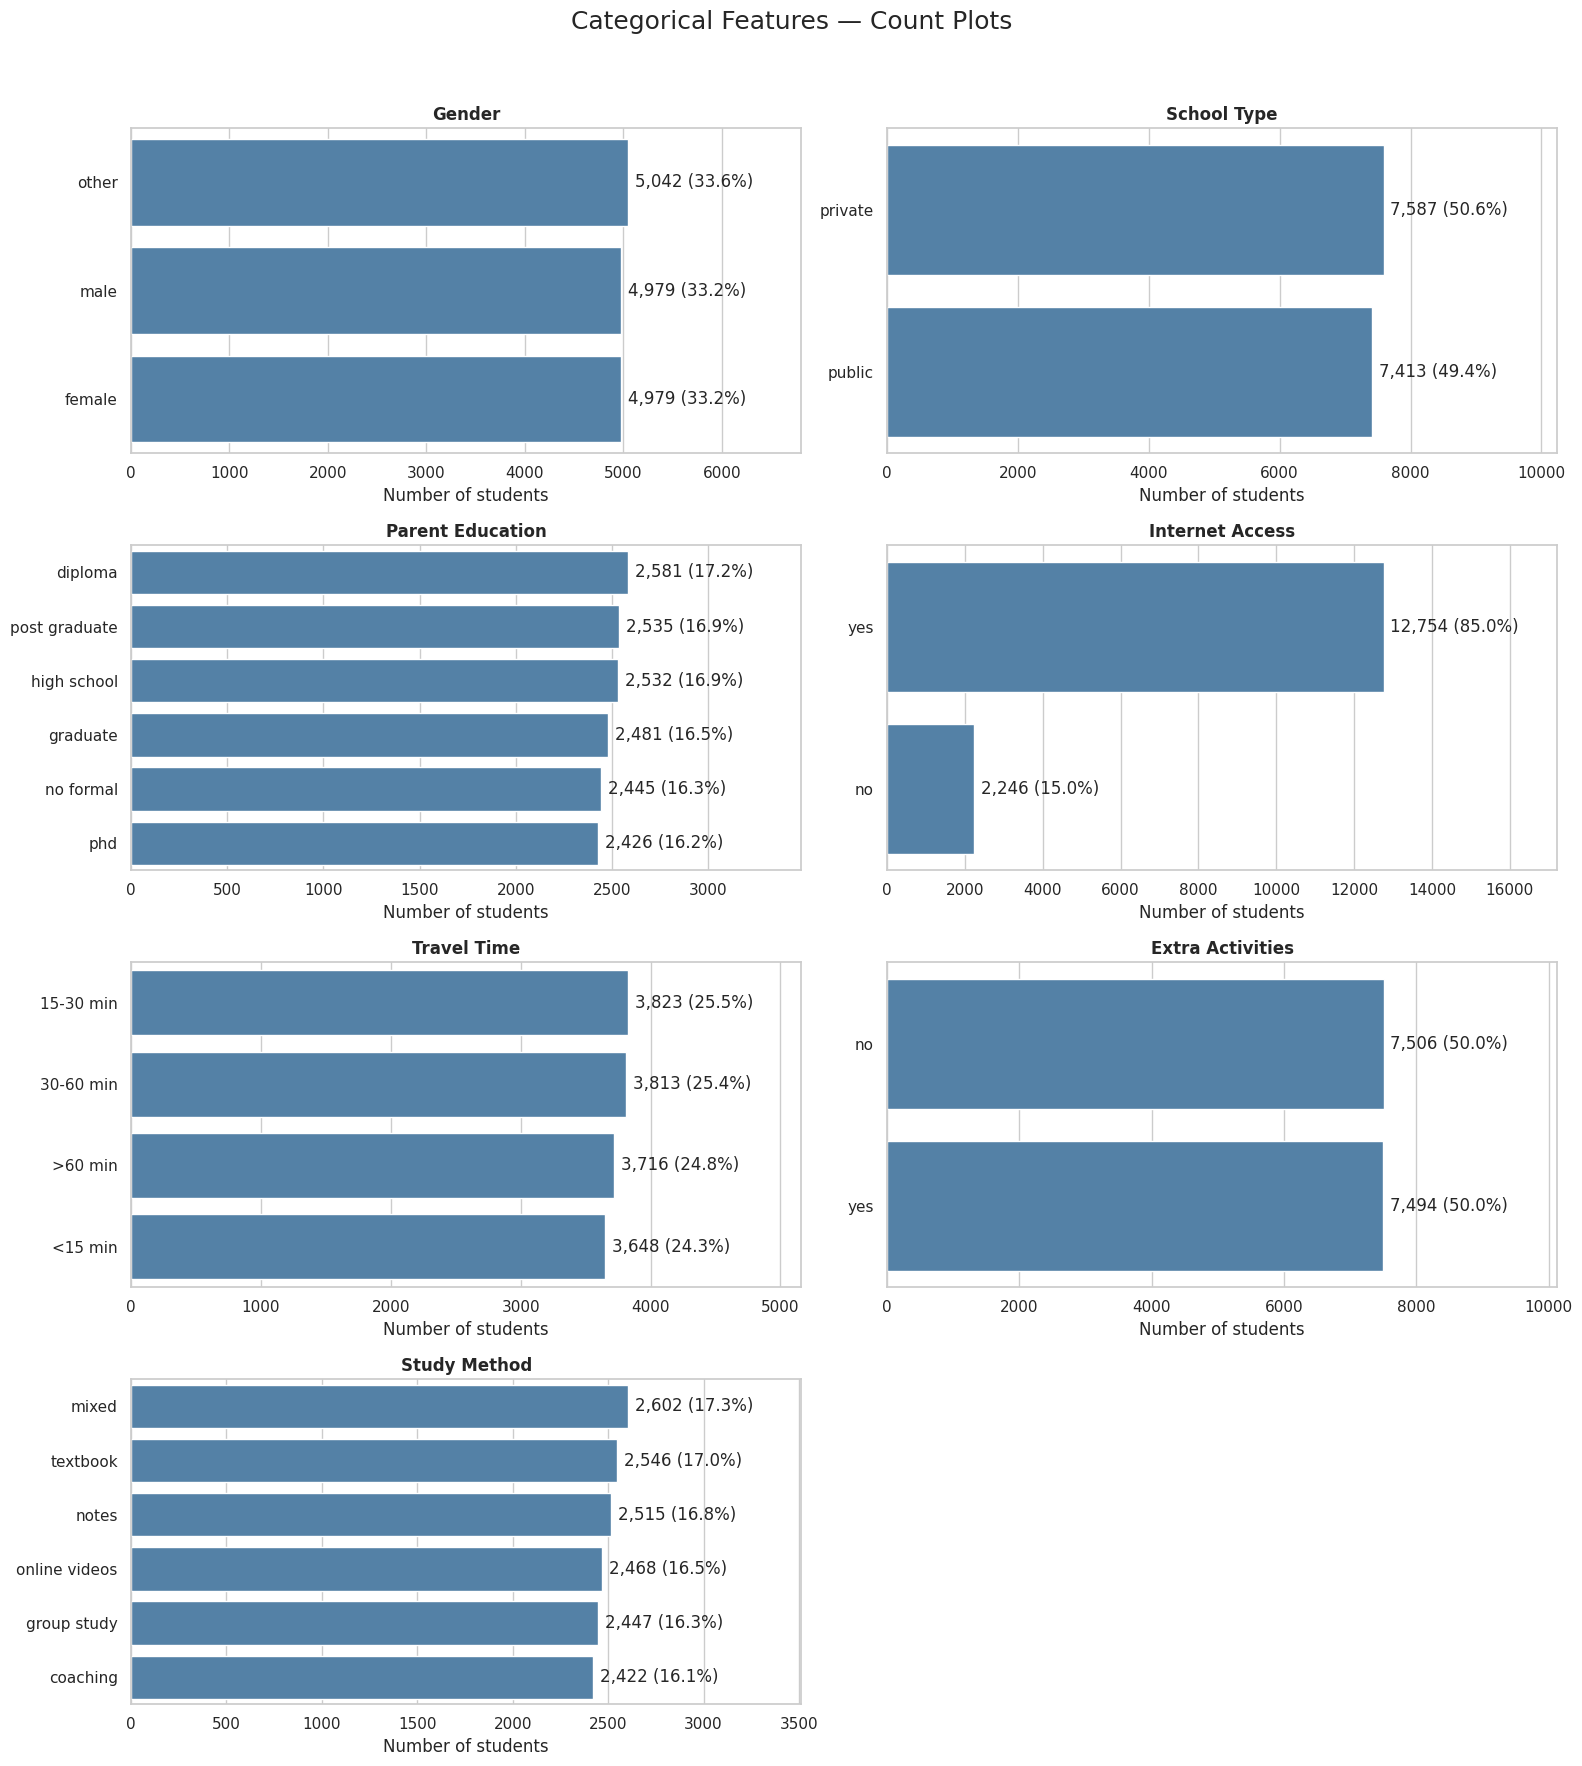

In [33]:
import matplotlib.pyplot as plt
import seaborn as sns


categorical_features = df.select_dtypes(
    include=["object", "string", "category"]
).columns.drop("final_grade", errors="ignore").tolist()

sns.set_theme(style="whitegrid")

n_cols = 2
n_rows = (len(categorical_features) + n_cols - 1) // n_cols

fig, axes = plt.subplots(
    n_rows, n_cols,
    figsize=(16, 4.5 * n_rows),
    squeeze=False
)
axes = axes.ravel()

for ax, column in zip(axes, categorical_features):
    values = df[column].astype("string").fillna("Missing")
    order = values.value_counts().index

    sns.countplot(
        y=values,
        order=order,
        color="steelblue",
        ax=ax
    )


    for bar in ax.patches:
        count = int(bar.get_width())

        ax.annotate(
            f"{count:,} ({100 * count / len(df):.1f}%)",
            xy=(count, bar.get_y() + bar.get_height() / 2),
            xytext=(5, 0),
            textcoords="offset points",
            va="center"
        )

    ax.set_title(column.replace("_", " ").title(), fontweight="bold")
    ax.set_xlabel("Number of students")
    ax.set_ylabel("")
    ax.set_xlim(0, values.value_counts().max() * 1.35)
    ax.grid(axis="y", visible=False)

for ax in axes[len(categorical_features):]:
    ax.set_visible(False)

fig.suptitle("Categorical Features — Count Plots", fontsize=18)
plt.tight_layout(rect=[0, 0, 1, 0.96])
plt.show()

In [34]:
y.value_counts()


,count
final_grade,
3,3770
4,3697
2,3378
1,1796
5,1638
6,721


Model formation

In [35]:
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier, AdaBoostClassifier, VotingClassifier
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB, MultinomialNB
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier

In [36]:
lg=LogisticRegression()
dc=DecisionTreeClassifier()
rf=RandomForestClassifier()
gb=GradientBoostingClassifier()
ada=AdaBoostClassifier()
svc=SVC()
knn=KNeighborsClassifier()
gnb=GaussianNB()
mnb=MultinomialNB()
lgbc=LGBMClassifier()
xgb=XGBClassifier()

In [37]:
model={'LR':lg,'DT':dc,'RF':rf,'GB':gb,'ADA':ada,'SVC':svc,'KNN':knn,'GNB':gnb,'MNB':mnb,'LGBM':lgbc,'XGB':xgb}


In [38]:
from sklearn.metrics import accuracy_score, classification_report


results = {}


for name, clf in model.items():
    try:
        print(f"Training {name}...")
        clf.fit(X_train_final, y_train)
        predictions = clf.predict(X_test_final)
        acc = accuracy_score(y_test, predictions)
        results[name] = acc
        print(f"{name} Accuracy: {acc:.4f}\n")
    except Exception as e:
        print(f"Could not train {name} due to: {e}\n")


print("=== Model Performance Leaderboard ===")
sorted_results = sorted(results.items(), key=lambda x: x[1], reverse=True)
for rank, (name, score) in enumerate(sorted_results, 1):
    print(f"{rank}. {name}: {score:.4f}")

Training LR...


/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


LR Accuracy: 0.6687

Training DT...
DT Accuracy: 0.9950

Training RF...
RF Accuracy: 0.9943

Training GB...
GB Accuracy: 0.9960

Training ADA...
ADA Accuracy: 0.9457

Training SVC...
SVC Accuracy: 0.9300

Training KNN...
KNN Accuracy: 0.8783

Training GNB...
GNB Accuracy: 0.8950

Training MNB...
MNB Accuracy: 0.4940

Training LGBM...
[LightGBM] [Warning] Found whitespace in feature_names, replace with underlines
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.001596 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 1396
[LightGBM] [Info] Number of data points in the train set: 12000, number of used features: 24
[LightGBM] [Info] Start training from score -2.142736
[LightGBM] [Info] Start training from score -1.488696
[LightGBM] [Info] Start training from score -1.370093
[LightGBM] [Info] Start training from score -1.404798
[LightGBM] [Inf


Model: LR


/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


              precision    recall  f1-score   support

           1       0.90      0.78      0.83       388
           2       0.75      0.77      0.76       670
           3       0.67      0.69      0.68       721
           4       0.62      0.70      0.66       752
           5       0.41      0.49      0.45       314
           6       0.85      0.07      0.13       155

    accuracy                           0.67      3000
   macro avg       0.70      0.58      0.59      3000
weighted avg       0.69      0.67      0.66      3000



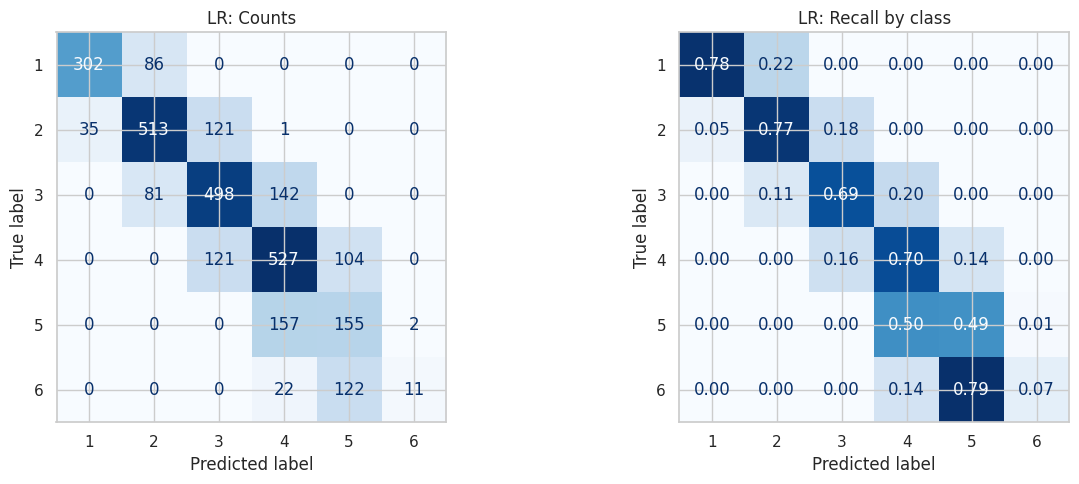

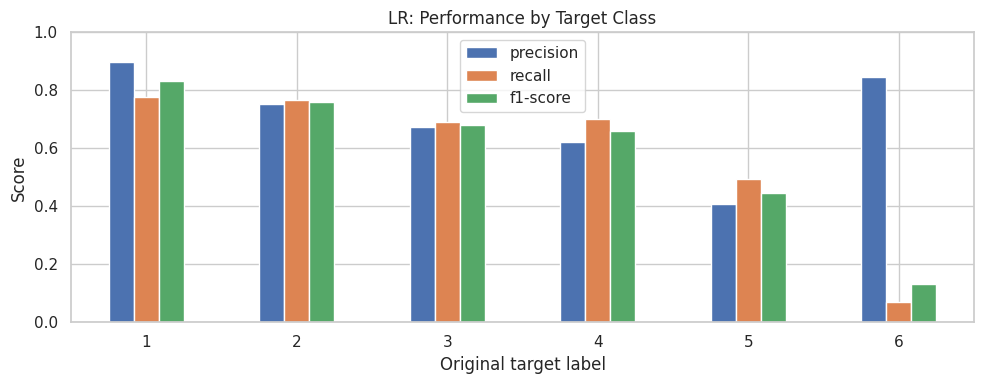

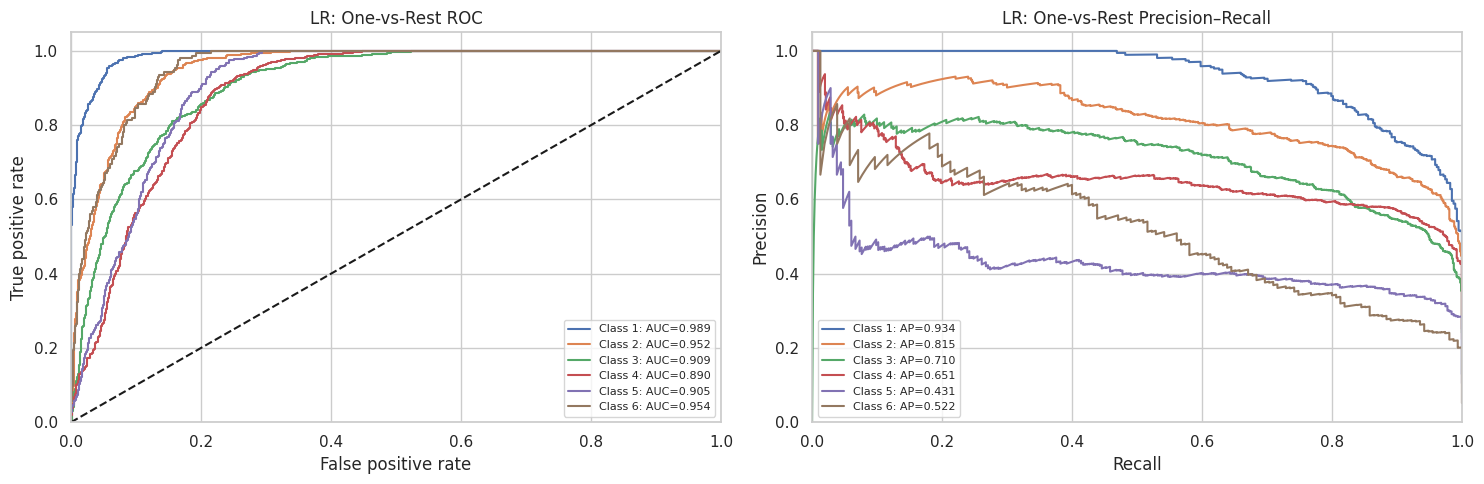


Model: DT
              precision    recall  f1-score   support

           1       0.99      1.00      1.00       388
           2       1.00      1.00      1.00       670
           3       1.00      0.99      1.00       721
           4       0.99      0.99      0.99       752
           5       0.99      0.99      0.99       314
           6       0.99      0.99      0.99       155

    accuracy                           0.99      3000
   macro avg       0.99      0.99      0.99      3000
weighted avg       0.99      0.99      0.99      3000



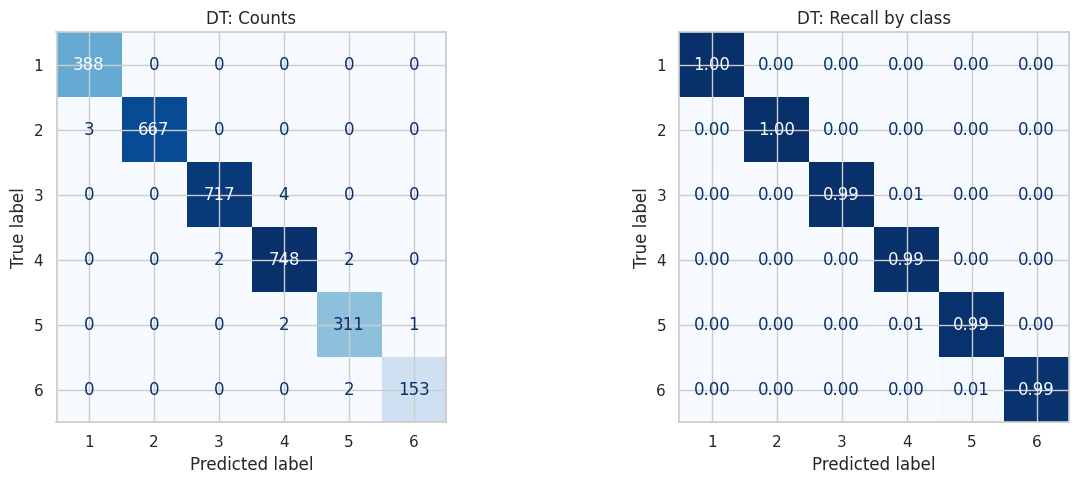

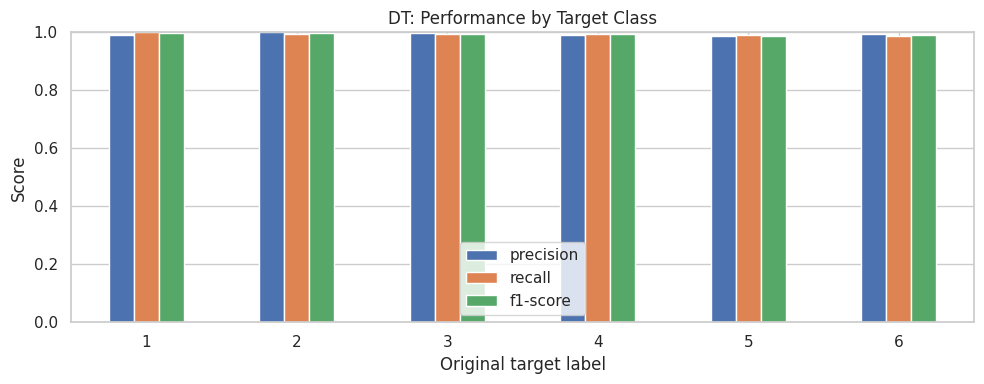

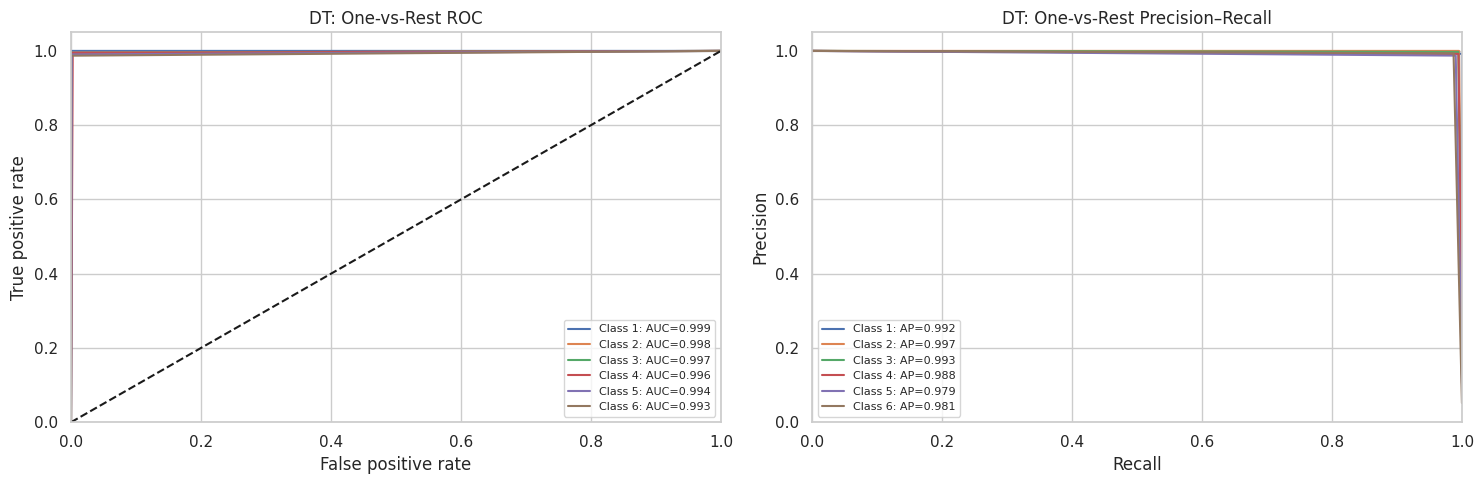


Model: RF
              precision    recall  f1-score   support

           1       1.00      1.00      1.00       388
           2       1.00      1.00      1.00       670
           3       1.00      1.00      1.00       721
           4       1.00      0.99      1.00       752
           5       0.98      1.00      0.99       314
           6       1.00      0.96      0.98       155

    accuracy                           1.00      3000
   macro avg       0.99      0.99      0.99      3000
weighted avg       1.00      1.00      1.00      3000



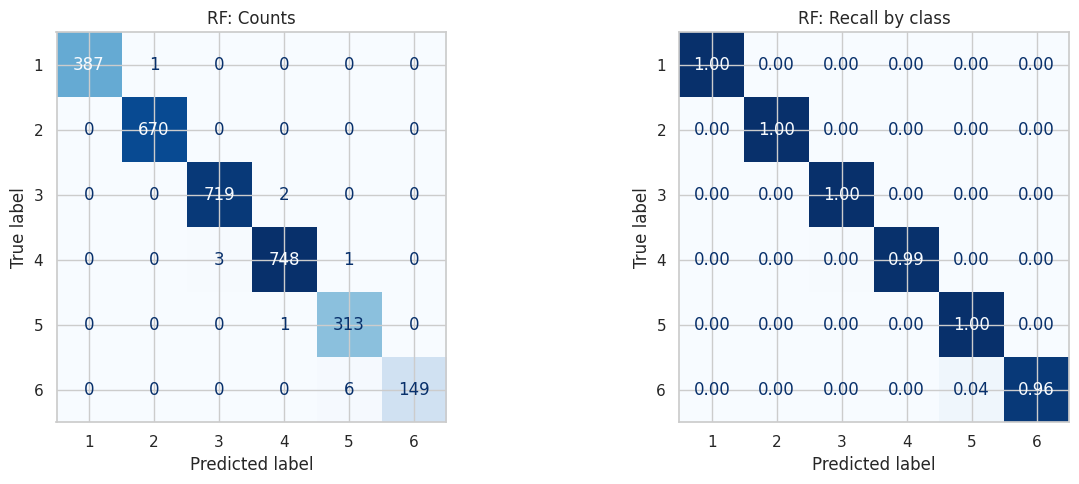

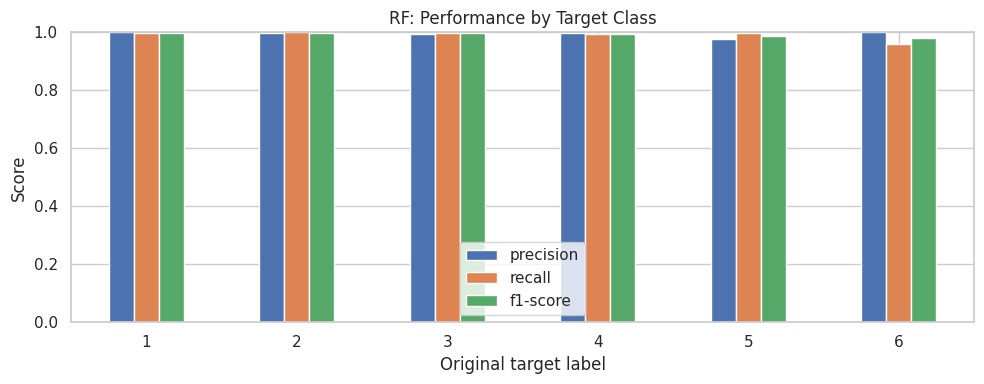

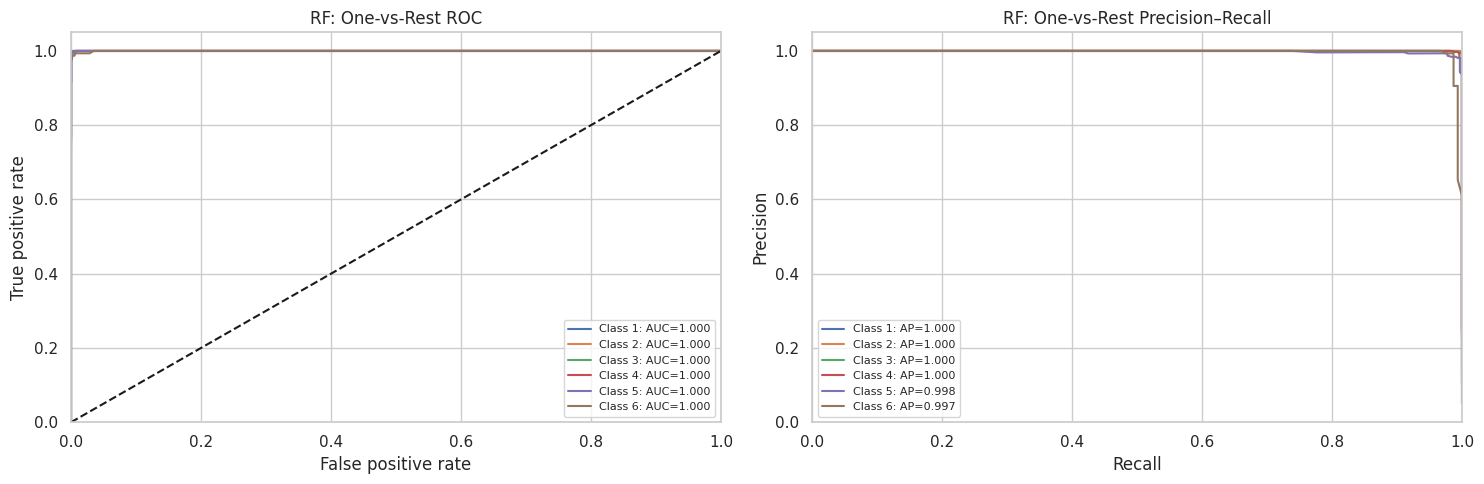


Model: GB
              precision    recall  f1-score   support

           1       0.99      1.00      1.00       388
           2       1.00      1.00      1.00       670
           3       1.00      1.00      1.00       721
           4       1.00      0.99      1.00       752
           5       0.99      0.99      0.99       314
           6       0.99      0.99      0.99       155

    accuracy                           1.00      3000
   macro avg       0.99      0.99      0.99      3000
weighted avg       1.00      1.00      1.00      3000



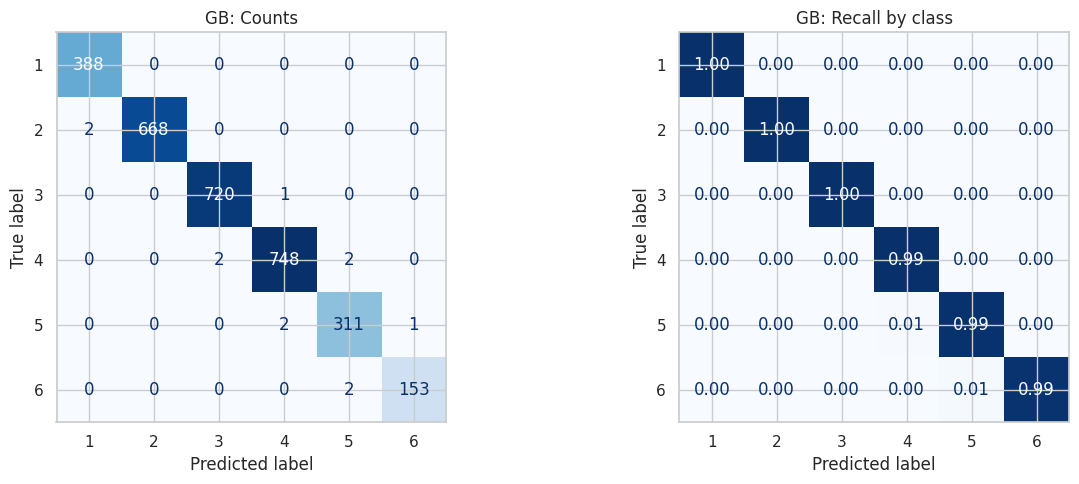

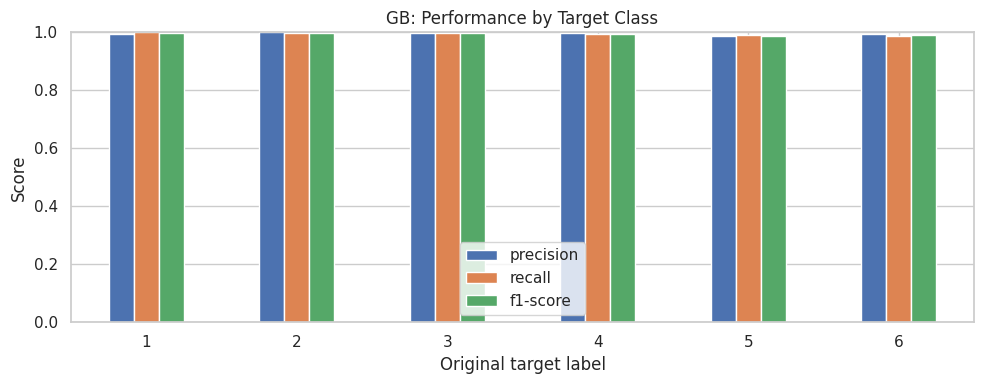

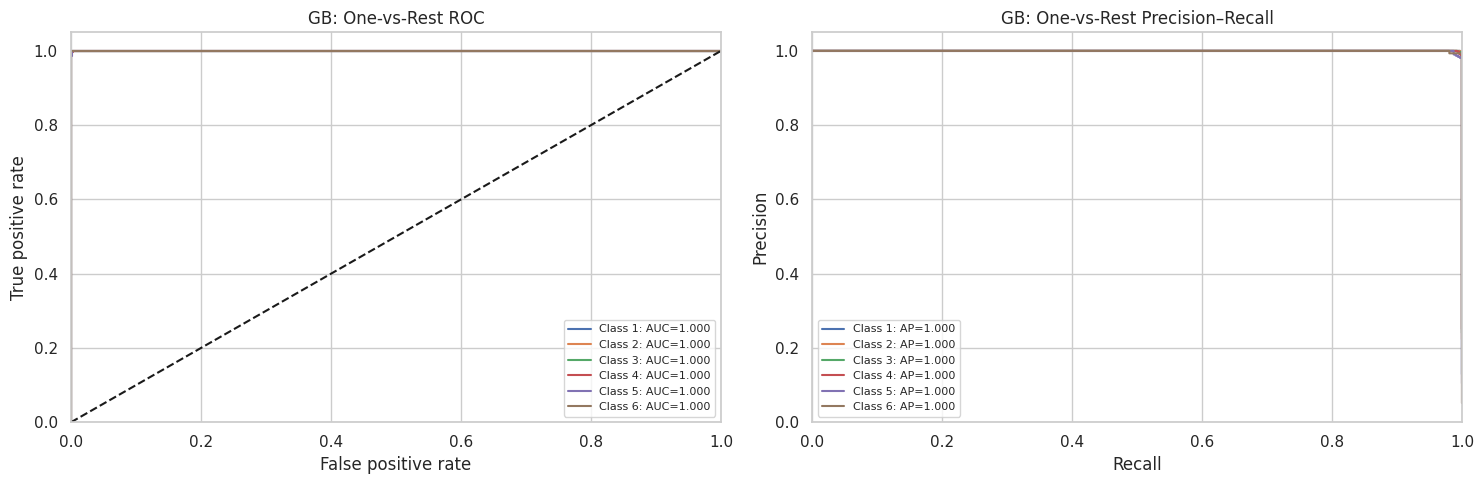


Model: ADA
              precision    recall  f1-score   support

           1       1.00      1.00      1.00       388
           2       1.00      1.00      1.00       670
           3       0.99      1.00      1.00       721
           4       1.00      0.99      1.00       752
           5       0.67      1.00      0.80       314
           6       0.00      0.00      0.00       155

    accuracy                           0.95      3000
   macro avg       0.78      0.83      0.80      3000
weighted avg       0.91      0.95      0.93      3000



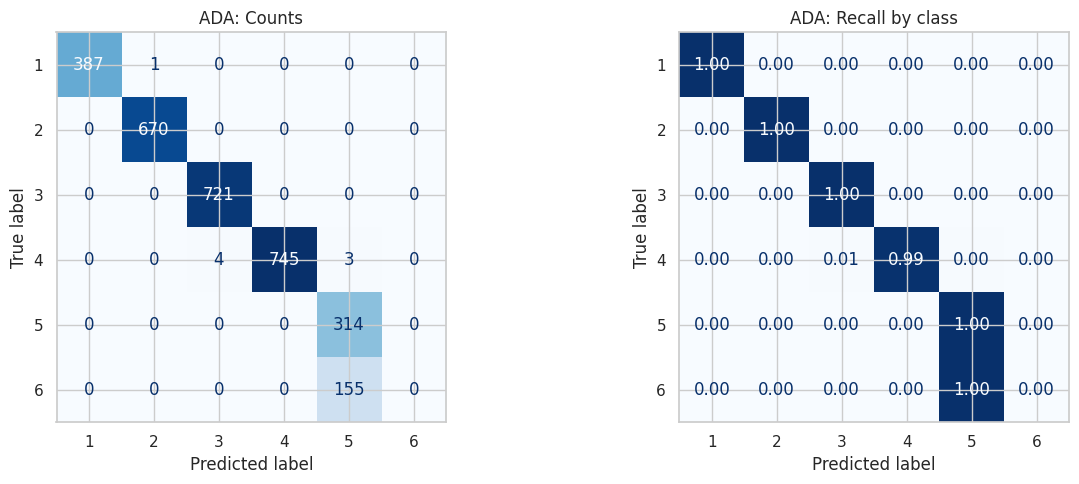

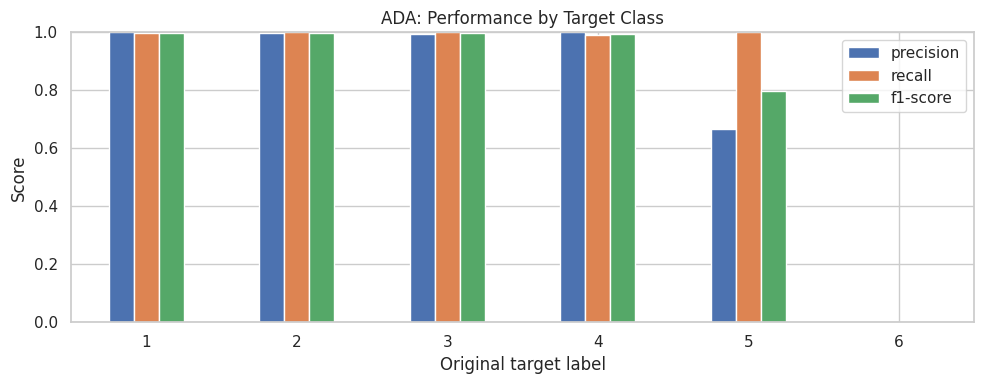

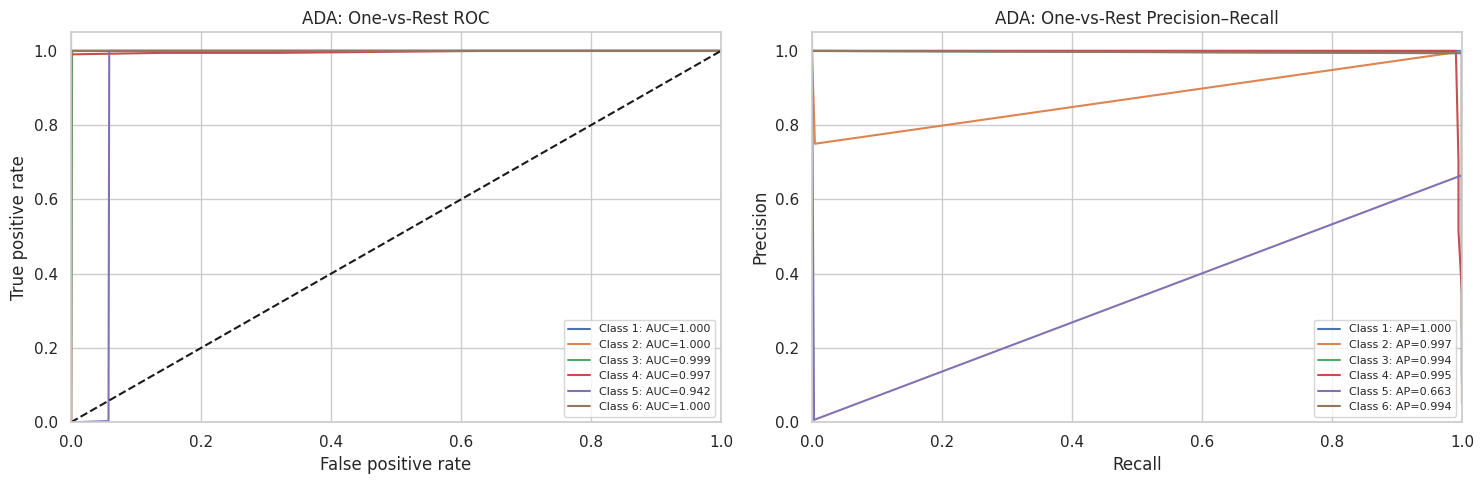


Model: SVC
              precision    recall  f1-score   support

           1       0.95      0.90      0.92       388
           2       0.91      0.95      0.93       670
           3       0.94      0.94      0.94       721
           4       0.94      0.94      0.94       752
           5       0.87      0.92      0.89       314
           6       0.98      0.84      0.90       155

    accuracy                           0.93      3000
   macro avg       0.93      0.91      0.92      3000
weighted avg       0.93      0.93      0.93      3000



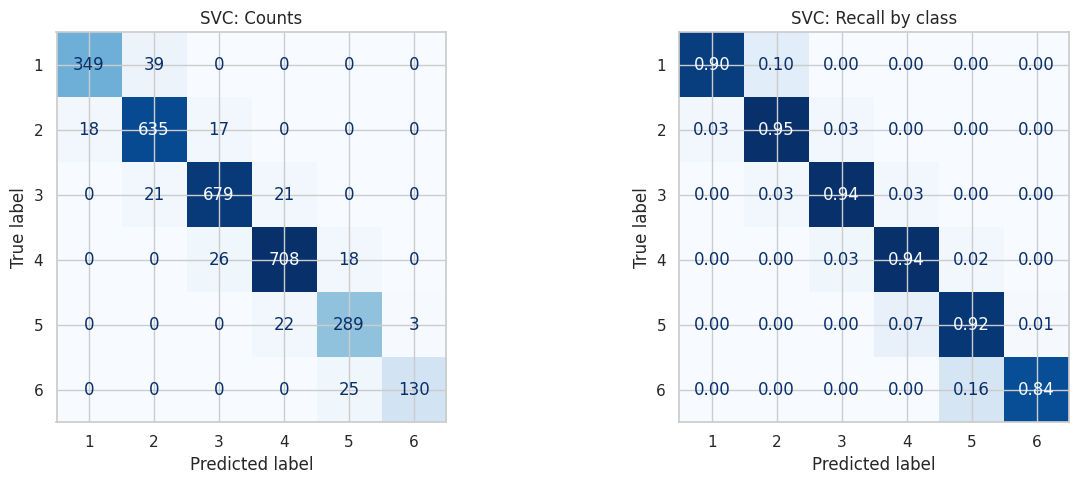

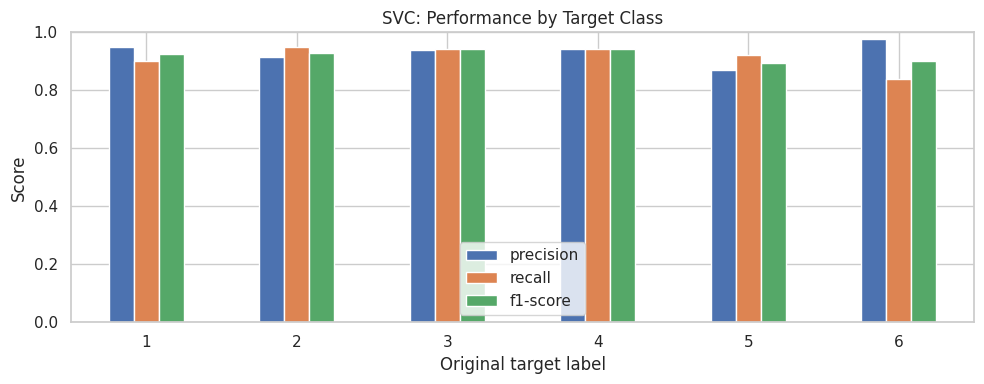

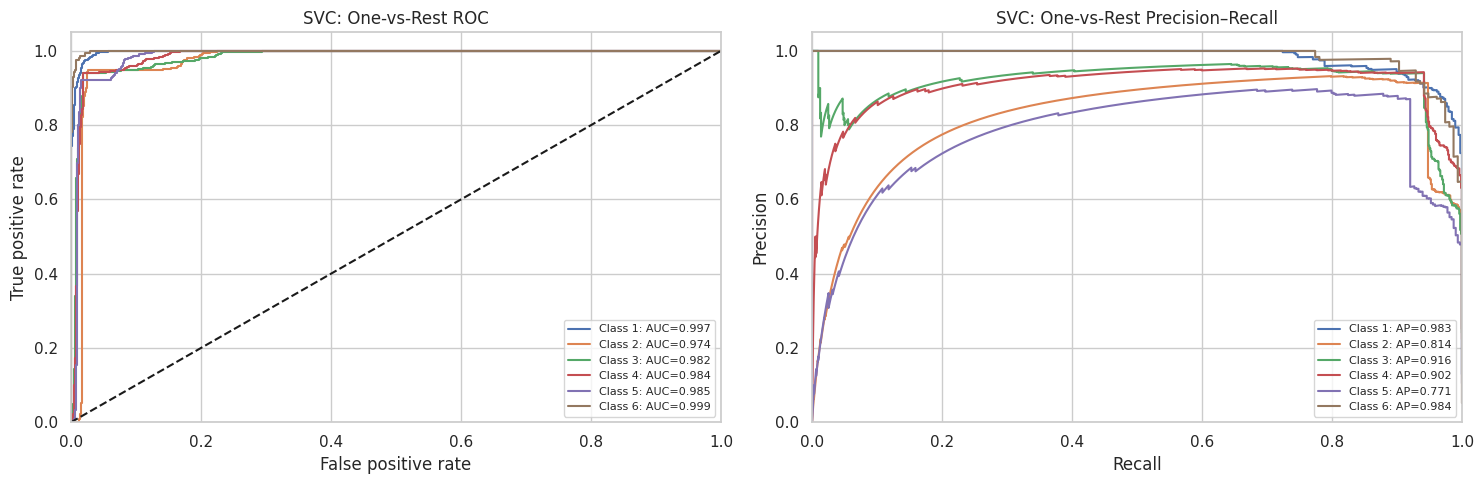


Model: KNN
              precision    recall  f1-score   support

           1       0.91      0.88      0.89       388
           2       0.87      0.89      0.88       670
           3       0.87      0.90      0.88       721
           4       0.89      0.88      0.89       752
           5       0.81      0.84      0.82       314
           6       0.93      0.81      0.87       155

    accuracy                           0.88      3000
   macro avg       0.88      0.87      0.87      3000
weighted avg       0.88      0.88      0.88      3000



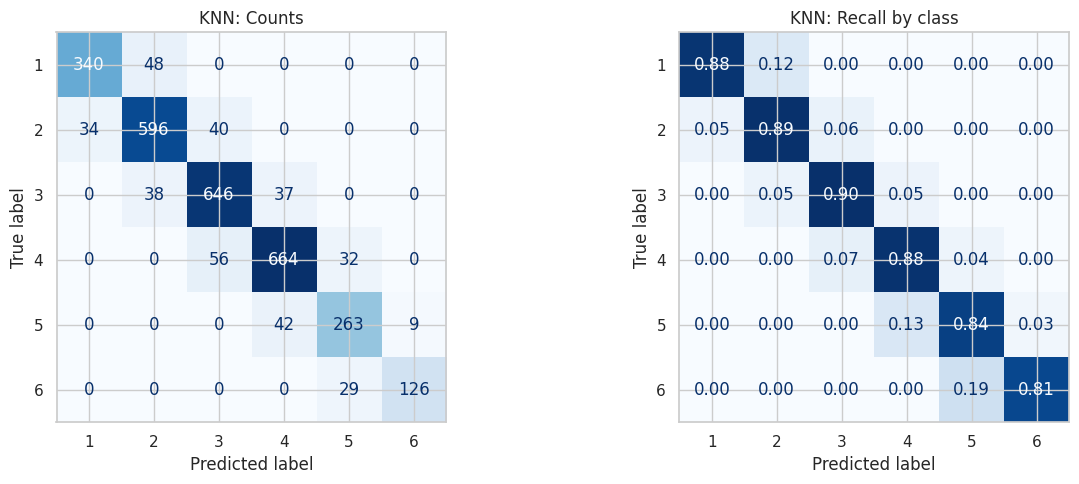

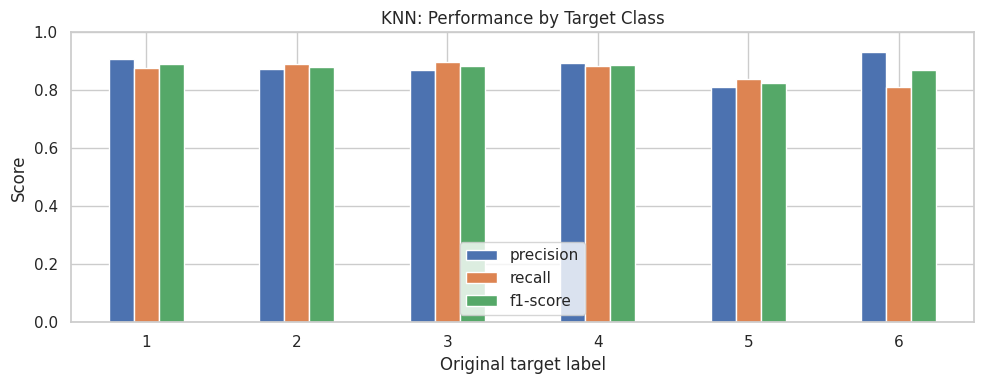

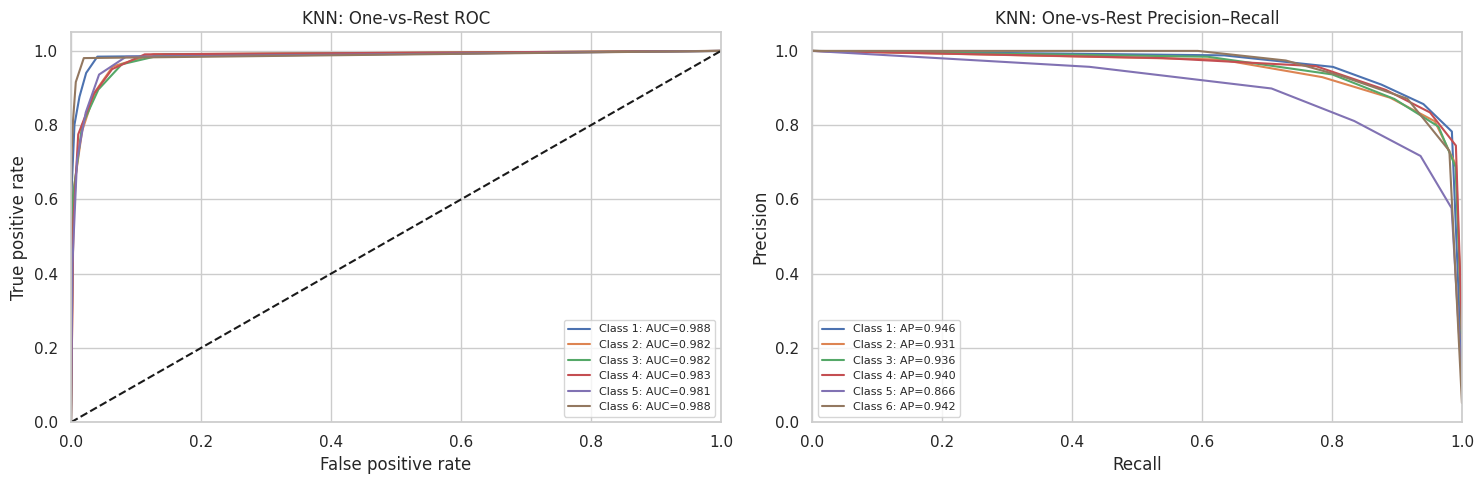


Model: GNB
              precision    recall  f1-score   support

           1       0.91      0.91      0.91       388
           2       0.88      0.90      0.89       670
           3       0.89      0.88      0.89       721
           4       0.92      0.88      0.90       752
           5       0.83      0.93      0.88       314
           6       0.99      0.93      0.96       155

    accuracy                           0.90      3000
   macro avg       0.90      0.90      0.90      3000
weighted avg       0.90      0.90      0.90      3000



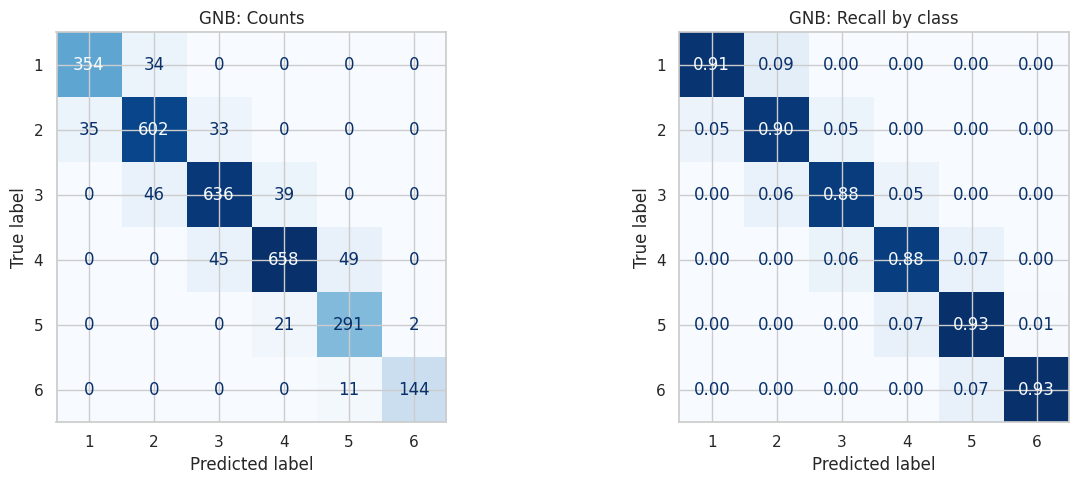

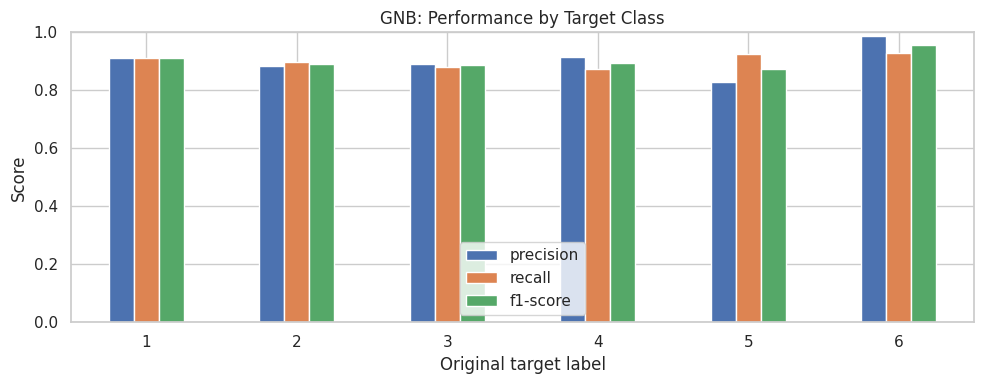

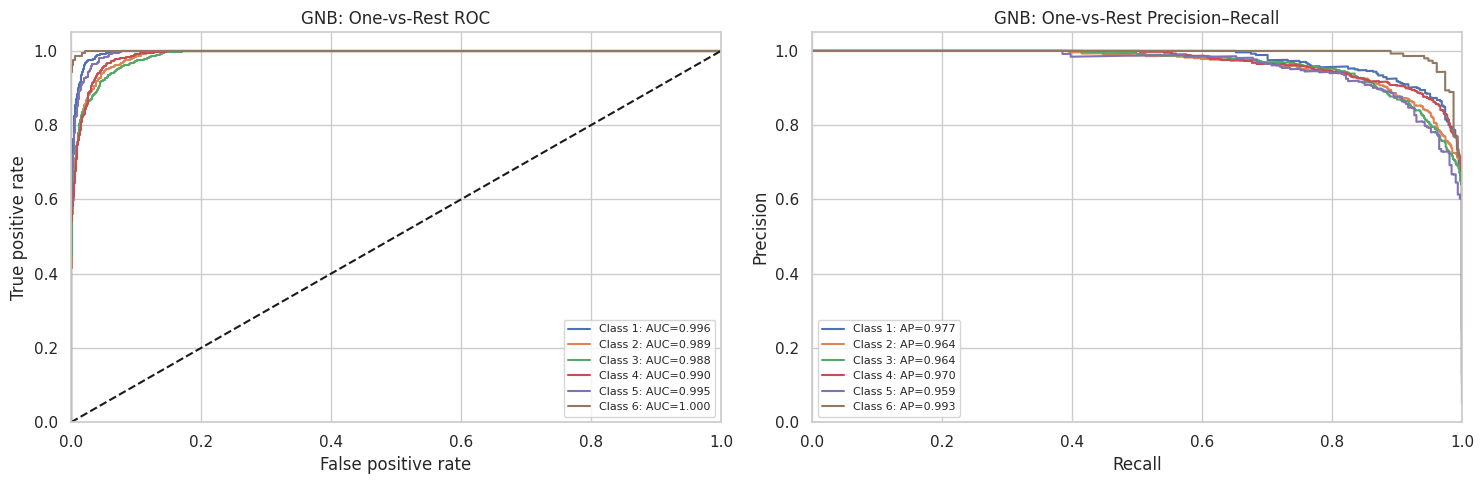


Model: MNB
              precision    recall  f1-score   support

           1       0.68      0.67      0.67       388
           2       0.56      0.54      0.55       670
           3       0.45      0.45      0.45       721
           4       0.44      0.55      0.49       752
           5       0.37      0.37      0.37       314
           6       1.00      0.02      0.04       155

    accuracy                           0.49      3000
   macro avg       0.58      0.43      0.43      3000
weighted avg       0.52      0.49      0.48      3000



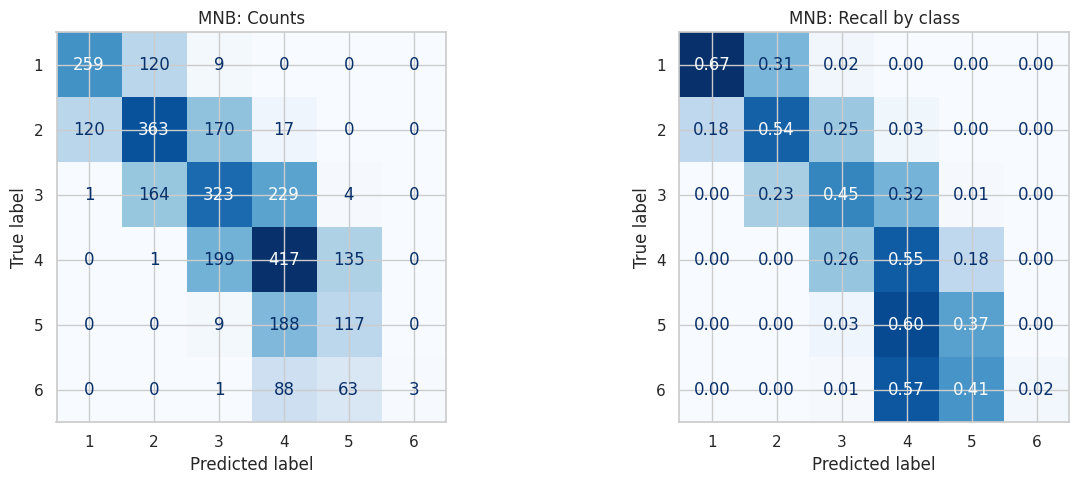

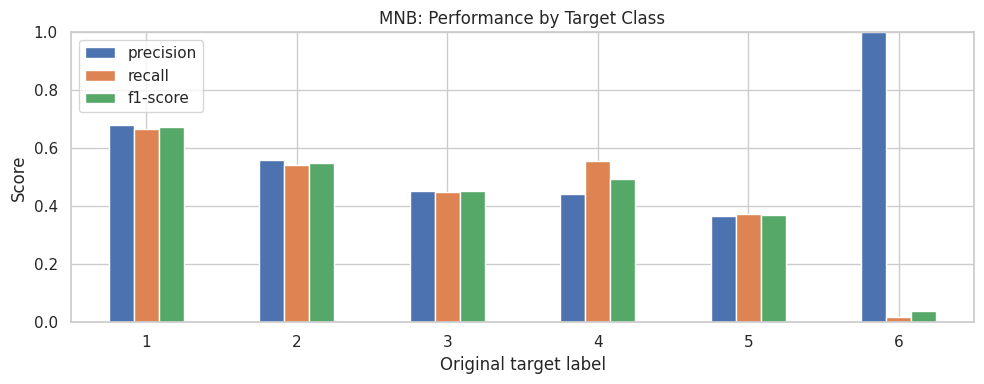

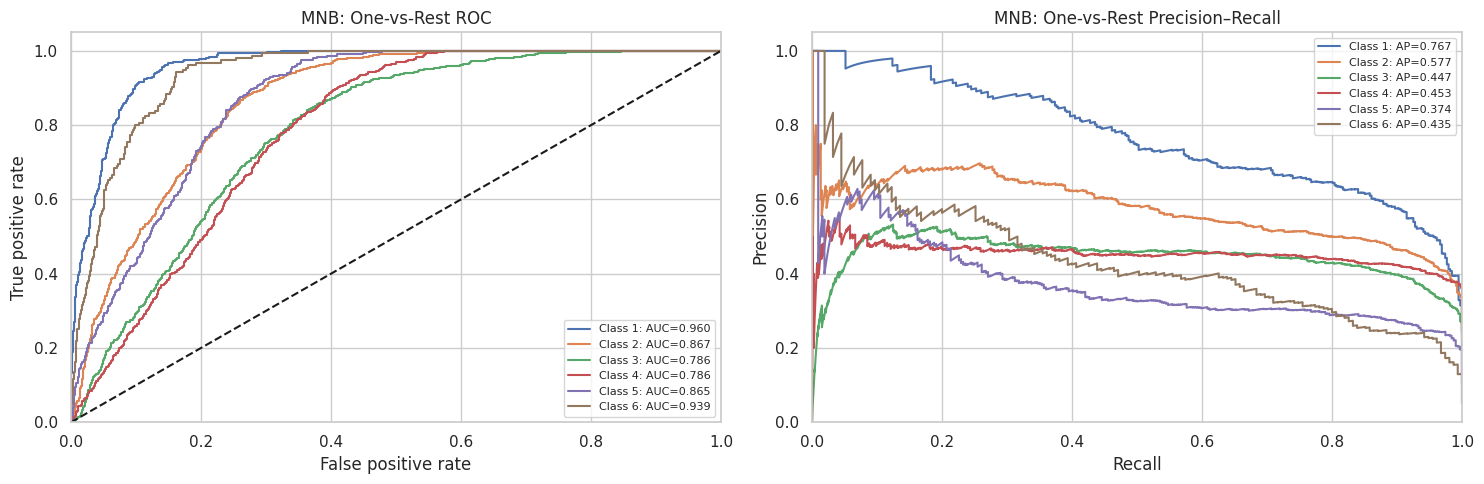


Model: LGBM
[LightGBM] [Warning] Found whitespace in feature_names, replace with underlines
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.000935 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 1396
[LightGBM] [Info] Number of data points in the train set: 12000, number of used features: 24
[LightGBM] [Info] Start training from score -2.142736
[LightGBM] [Info] Start training from score -1.488696
[LightGBM] [Info] Start training from score -1.370093
[LightGBM] [Info] Start training from score -1.404798
[LightGBM] [Info] Start training from score -2.204249
[LightGBM] [Info] Start training from score -3.054068
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[Ligh

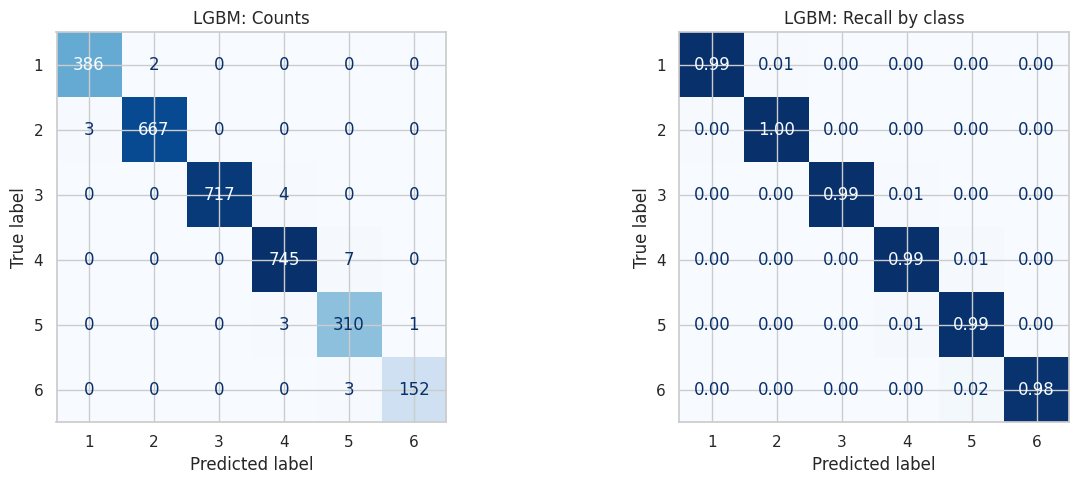

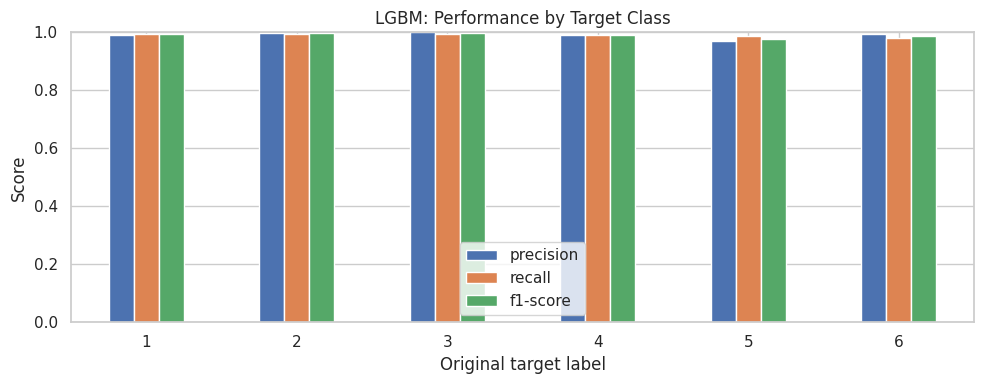

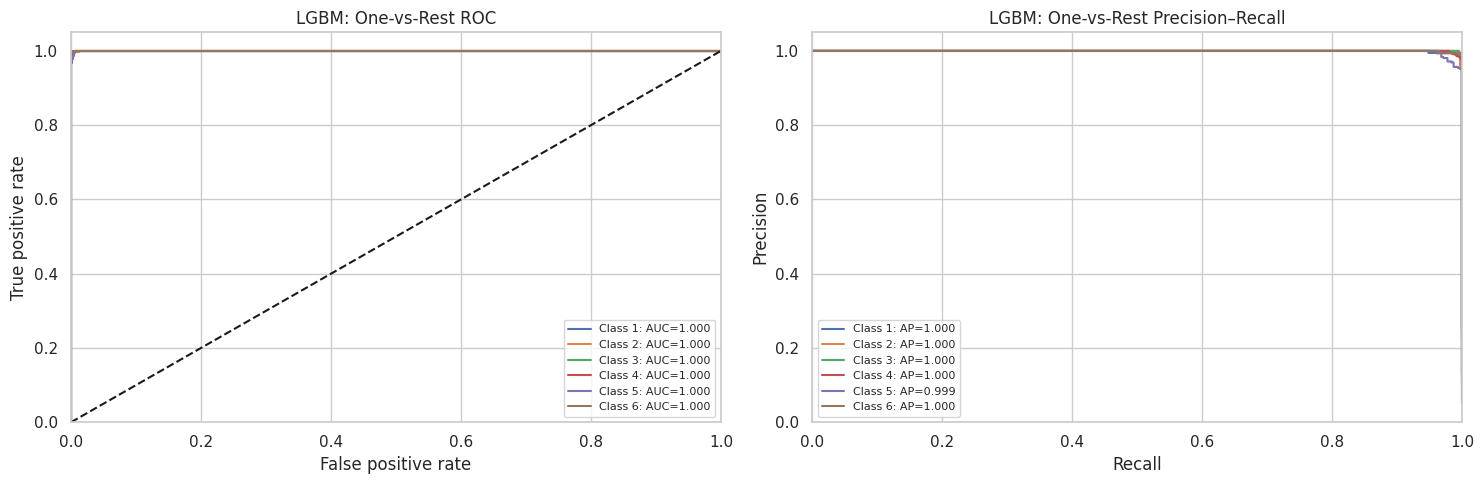


Model: XGB
              precision    recall  f1-score   support

           1       1.00      1.00      1.00       388
           2       1.00      1.00      1.00       670
           3       1.00      0.99      1.00       721
           4       0.99      1.00      0.99       752
           5       0.98      0.99      0.99       314
           6       0.99      0.96      0.98       155

    accuracy                           0.99      3000
   macro avg       0.99      0.99      0.99      3000
weighted avg       0.99      0.99      0.99      3000



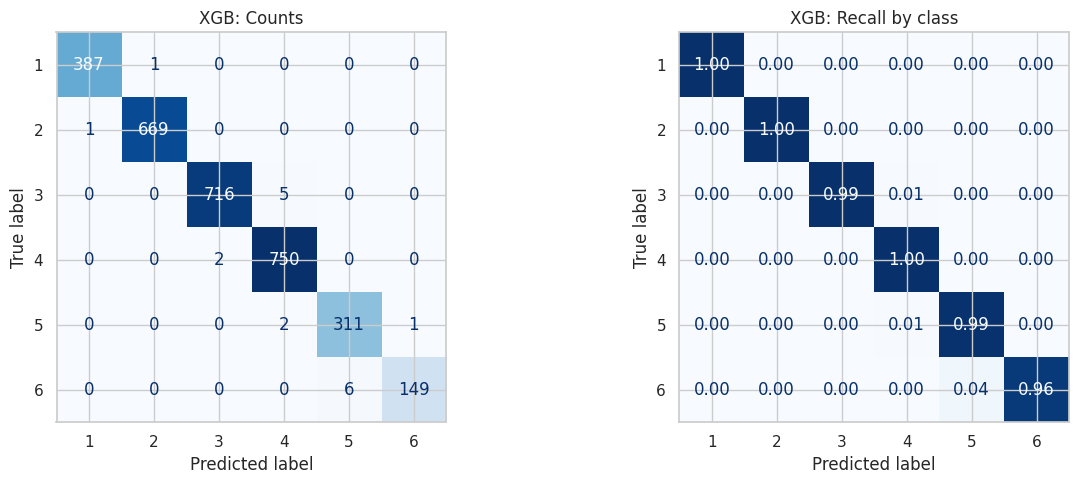

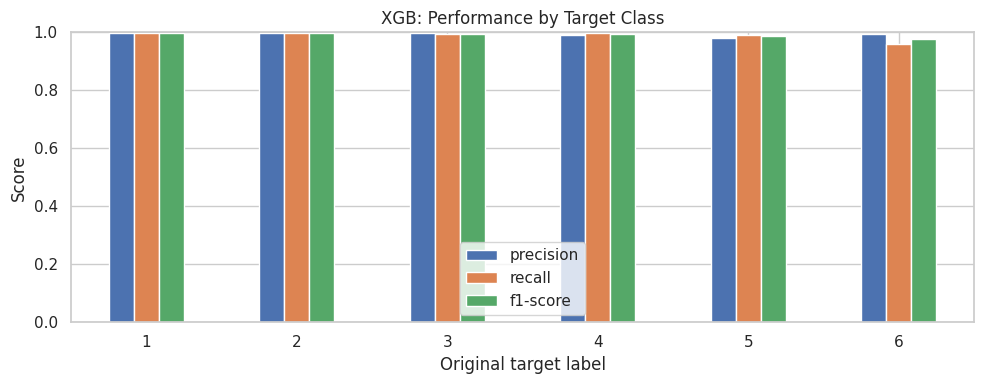

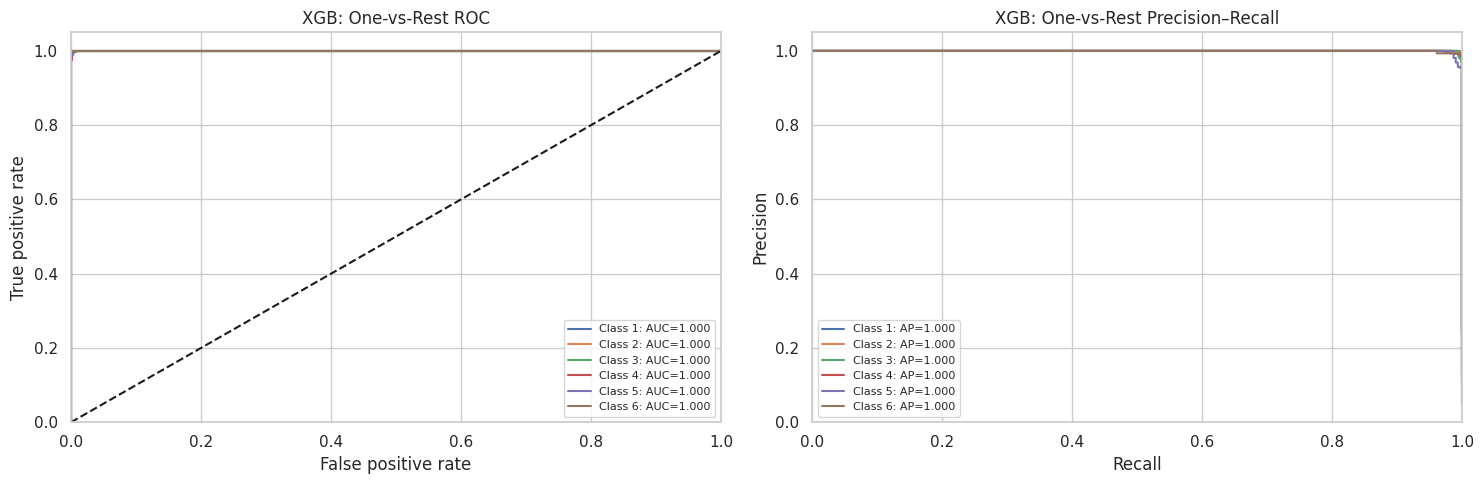


=== Test-set Model Comparison ===
       Accuracy  Balanced accuracy  Macro precision  Macro recall  Macro F1  Weighted F1  Macro ROC AUC  Macro AP
Model                                                                                                            
GB       0.9960             0.9946           0.9948        0.9946    0.9947       0.9960         1.0000    0.9999
DT       0.9947             0.9937           0.9937        0.9937    0.9937       0.9947         0.9963    0.9884
RF       0.9953             0.9912           0.9947        0.9912    0.9929       0.9953         0.9999    0.9992
XGB      0.9940             0.9897           0.9931        0.9897    0.9913       0.9940         1.0000    0.9998
LGBM     0.9923             0.9906           0.9904        0.9906    0.9904       0.9923         0.9999    0.9997
SVC      0.9300             0.9149           0.9326        0.9149    0.9226       0.9300         0.9868    0.8949
GNB      0.8950             0.9040           0.9025  

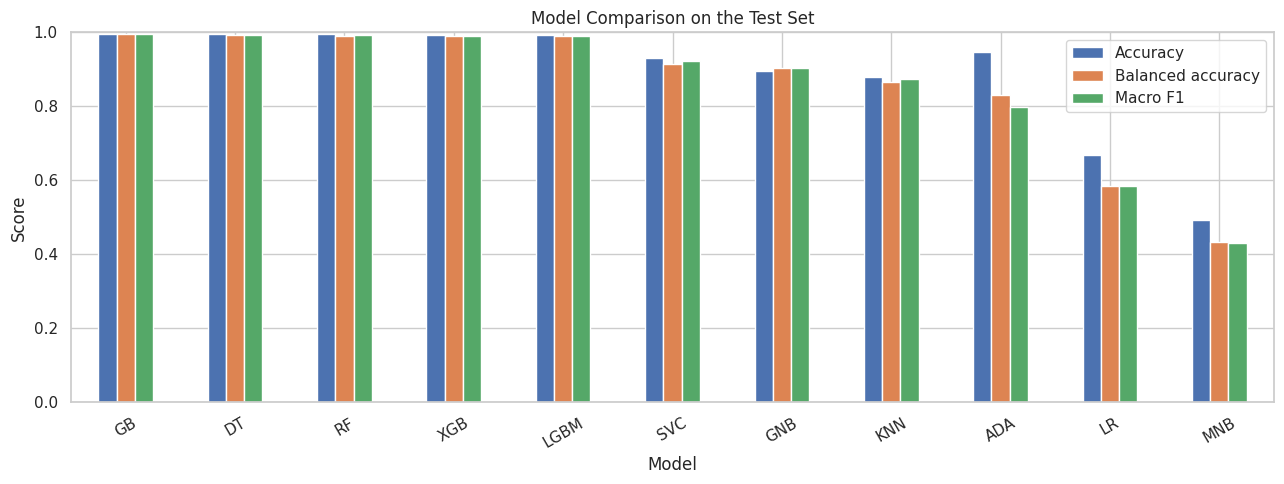

In [39]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.base import clone
from sklearn.preprocessing import LabelEncoder, label_binarize
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    ConfusionMatrixDisplay,
    roc_curve,
    roc_auc_score,
    precision_recall_curve,
    average_precision_score
)


target_encoder = LabelEncoder()
y_train_shifted = target_encoder.fit_transform(y_train)
y_test_shifted = target_encoder.transform(y_test)

classes = np.arange(len(target_encoder.classes_))
class_names = [
    str(label) for label in target_encoder.classes_
]

results = {}
metric_rows = []
trained_models = {}

for name, original_model in model.items():
    print(f"\n{'=' * 55}\nModel: {name}")

    clf = clone(original_model)

    try:
        clf.fit(X_train_final, y_train_shifted)
        predictions = clf.predict(X_test_final)

    except Exception as error:
        print(f"Training/prediction failed: {error}")
        continue

    trained_models[name] = clf

    row = {
        "Model": name,
        "Accuracy": accuracy_score(y_test_shifted, predictions),
        "Balanced accuracy": balanced_accuracy_score(
            y_test_shifted, predictions
        ),
        "Macro precision": precision_score(
            y_test_shifted, predictions,
            average="macro", zero_division=0
        ),
        "Macro recall": recall_score(
            y_test_shifted, predictions,
            average="macro", zero_division=0
        ),
        "Macro F1": f1_score(
            y_test_shifted, predictions,
            average="macro", zero_division=0
        ),
        "Weighted F1": f1_score(
            y_test_shifted, predictions,
            average="weighted", zero_division=0
        ),
        "Macro ROC AUC": np.nan,
        "Macro AP": np.nan
    }

    results[name] = row["Accuracy"]

    print(classification_report(
        y_test_shifted,
        predictions,
        labels=classes,
        target_names=class_names,
        zero_division=0
    ))
    fig, axes = plt.subplots(1, 2, figsize=(13, 5))

    for ax, normalization, title in [
        (axes[0], None, "Counts"),
        (axes[1], "true", "Recall by class")
    ]:
        ConfusionMatrixDisplay.from_predictions(
            y_test_shifted,
            predictions,
            labels=classes,
            display_labels=class_names,
            normalize=normalization,
            values_format="d" if normalization is None else ".2f",
            cmap="Blues",
            colorbar=False,
            ax=ax
        )
        ax.set_title(f"{name}: {title}")

    plt.tight_layout()
    plt.show()


    report = classification_report(
        y_test_shifted,
        predictions,
        labels=classes,
        target_names=class_names,
        output_dict=True,
        zero_division=0
    )

    class_metrics = pd.DataFrame(report).T.loc[
        class_names, ["precision", "recall", "f1-score"]
    ]

    class_metrics.plot(
        kind="bar",
        figsize=(10, 4),
        ylim=(0, 1)
    )
    plt.title(f"{name}: Performance by Target Class")
    plt.xlabel("Original target label")
    plt.ylabel("Score")
    plt.xticks(rotation=0)
    plt.tight_layout()
    plt.show()


    scores = None
    probabilities = None

    try:
        if hasattr(clf, "predict_proba"):
            probabilities = clf.predict_proba(X_test_final)
            scores = probabilities

        elif hasattr(clf, "decision_function"):

            scores = clf.decision_function(X_test_final)

        if scores is not None:

            column_order = [
                np.where(clf.classes_ == label)[0][0]
                for label in classes
            ]
            scores = np.asarray(scores)[:, column_order]

            if probabilities is not None:
                probabilities = np.asarray(probabilities)[:, column_order]

            binary_target = label_binarize(
                y_test_shifted, classes=classes
            )

            fig, axes = plt.subplots(1, 2, figsize=(15, 5))
            auc_values = []
            ap_values = []

            for i, label in enumerate(class_names):
                binary_class = binary_target[:, i]


                if np.unique(binary_class).size < 2:
                    continue

                fpr, tpr, _ = roc_curve(
                    binary_class, scores[:, i]
                )
                auc = roc_auc_score(
                    binary_class, scores[:, i]
                )
                auc_values.append(auc)

                axes[0].plot(
                    fpr, tpr,
                    label=f"Class {label}: AUC={auc:.3f}"
                )

                precision, recall, _ = precision_recall_curve(
                    binary_class, scores[:, i]
                )
                ap = average_precision_score(
                    binary_class, scores[:, i]
                )
                ap_values.append(ap)

                axes[1].plot(
                    recall, precision,
                    label=f"Class {label}: AP={ap:.3f}"
                )

            axes[0].plot([0, 1], [0, 1], "k--")
            axes[0].set(
                title=f"{name}: One-vs-Rest ROC",
                xlabel="False positive rate",
                ylabel="True positive rate"
            )
            axes[1].set(
                title=f"{name}: One-vs-Rest Precision–Recall",
                xlabel="Recall",
                ylabel="Precision"
            )

            for ax in axes:
                ax.legend(fontsize=8)
                ax.set_xlim(0, 1)
                ax.set_ylim(0, 1.05)

            plt.tight_layout()
            plt.show()


            if auc_values:
                row["Macro ROC AUC"] = np.mean(auc_values)

            if ap_values:
                row["Macro AP"] = np.mean(ap_values)

        else:
            print("ROC/PR curves unavailable: no continuous scores.")

    except Exception as error:
        print(f"ROC/PR evaluation unavailable: {error}")

    metric_rows.append(row)


if metric_rows:
    comparison_df = (
        pd.DataFrame(metric_rows)
        .set_index("Model")
        .sort_values("Macro F1", ascending=False)
    )

    print("\n=== Test-set Model Comparison ===")
    print(comparison_df.round(4).to_string())

    comparison_df[
        ["Accuracy", "Balanced accuracy", "Macro F1"]
    ].plot(
        kind="bar",
        figsize=(13, 5),
        ylim=(0, 1)
    )

    plt.title("Model Comparison on the Test Set")
    plt.ylabel("Score")
    plt.xlabel("Model")
    plt.xticks(rotation=30)
    plt.tight_layout()
    plt.show()

else:
    print("No models completed successfully.")

In [40]:
X_train_final.head()

,onehot__gender_female,onehot__gender_male,onehot__gender_other,onehot__internet_access_no,onehot__internet_access_yes,onehot__school_type_private,onehot__school_type_public,onehot__study_method_coaching,onehot__study_method_group study,onehot__study_method_mixed,...,onehot__extra_activities_yes,numeric__age,numeric__parent_education,numeric__study_hours,numeric__attendance_percentage,numeric__travel_time,numeric__math_score,numeric__science_score,numeric__english_score,numeric__overall_score
9839,0.0,1.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0,0.0,...,0.0,16.0,1.0,1.6,73.5,4.0,59.1,57.7,53.0,44.2
9680,0.0,0.0,1.0,0.0,1.0,0.0,1.0,0.0,0.0,1.0,...,0.0,14.0,3.0,7.6,89.6,4.0,100.0,86.5,100.0,100.0
7093,0.0,0.0,1.0,0.0,1.0,0.0,1.0,0.0,0.0,1.0,...,0.0,16.0,0.0,0.8,60.6,1.0,20.9,39.8,41.2,25.0
11293,0.0,0.0,1.0,0.0,1.0,1.0,0.0,0.0,0.0,0.0,...,0.0,17.0,4.0,6.2,63.3,2.0,64.2,68.1,71.4,66.9
820,0.0,0.0,1.0,0.0,1.0,0.0,1.0,0.0,1.0,0.0,...,1.0,14.0,0.0,7.5,89.9,1.0,91.5,88.9,89.1,100.0


In [41]:
!pip install streamlit

CV accuracy: 0.9971 ± 0.0010
CV balanced_accuracy: 0.9969 ± 0.0010
CV macro_f1: 0.9971 ± 0.0007

Test accuracy: 0.9960
Test balanced accuracy: 0.9946

               precision    recall  f1-score   support

           1       0.99      1.00      1.00       388
           2       1.00      1.00      1.00       670
           3       1.00      1.00      1.00       721
           4       1.00      0.99      1.00       752
           5       0.99      0.99      0.99       314
           6       0.99      0.99      0.99       155

    accuracy                           1.00      3000
   macro avg       0.99      0.99      0.99      3000
weighted avg       1.00      1.00      1.00      3000



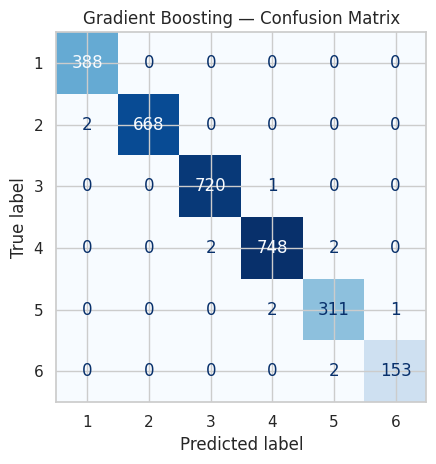

In [42]:
import streamlit as st
import numpy as np
from sklearn.pipeline import Pipeline
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.metrics import (
    accuracy_score, balanced_accuracy_score,
    classification_report, ConfusionMatrixDisplay
)
import matplotlib.pyplot as plt


y_train = df.loc[X_train_final.index, "final_grade"].copy()
y_test = df.loc[X_test_final.index, "final_grade"].copy()


pipeline = Pipeline([
    ("preprocessing", "passthrough"),
    ("classifier", GradientBoostingClassifier(random_state=42))
])


cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

scores = cross_validate(
    pipeline,
    X_train_final, y_train,
    cv=cv,
    scoring={
        "accuracy": "accuracy",
        "balanced_accuracy": "balanced_accuracy",
        "macro_f1": "f1_macro"
    },
    n_jobs=-1,
    error_score="raise"
)

for metric in ["accuracy", "balanced_accuracy", "macro_f1"]:
    values = scores[f"test_{metric}"]
    print(f"CV {metric}: {values.mean():.4f} ± {values.std():.4f}")


pipeline.fit(X_train_final, y_train)
y_pred = pipeline.predict(X_test_final)

print(f"\nTest accuracy: {accuracy_score(y_test, y_pred):.4f}")
print(
    f"Test balanced accuracy: "
    f"{balanced_accuracy_score(y_test, y_pred):.4f}"
)
print("\n", classification_report(y_test, y_pred, zero_division=0))

ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred, cmap="Blues", colorbar=False
)
plt.title("Gradient Boosting — Confusion Matrix")
plt.tight_layout()
plt.show()


In [43]:
import joblib

joblib.dump(
    {
        "model": pipeline,
        "feature_columns": X_train_final.columns.tolist()
    },
    "student_grade_model.joblib"
)

['student_grade_model.joblib']

In [44]:
@st.cache_resource
def load_model():
    path = Path("/content/student_grade_model.joblib")

    if not path.exists():
        st.error("Model file missing. Run the model-saving cell first.")
        st.stop()

    return joblib.load(path)

In [45]:
%%writefile /content/app.py

Writing /content/app.py


In [46]:
%%writefile /content/app.py

Overwriting /content/app.py


In [47]:
!pip install pyngrok

In [48]:
from pathlib import Path

app_path = Path("/content/app.py")

if not app_path.exists():
    raise FileNotFoundError(
        "Create /content/app.py first using %%writefile /content/app.py."
    )

code = app_path.read_text()

code = code.replace(
    'Path(__file__).parent / "student_grade_model.joblib"',
    'Path("/content/student_grade_model.joblib")'
)
code = code.replace(
    "Path(__file__).parent / 'student_grade_model.joblib'",
    'Path("/content/student_grade_model.joblib")'
)

app_path.write_text(code)

remaining = [
    f"Line {i}: {line}"
    for i, line in enumerate(code.splitlines(), 1)
    if "__file__" in line
]

if remaining:
    print("Other references remain:\n" + "\n".join(remaining))
else:
    print("Fixed. Rerun your Streamlit launch cell and refresh the app.")

Fixed. Rerun your Streamlit launch cell and refresh the app.


In [49]:
from pathlib import Path
from google.colab import files

path = Path("/content/__init__.py")
path.touch(exist_ok=True)

files.download(str(path))

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [50]:
import subprocess
import time
import requests
from getpass import getpass
from pyngrok import ngrok


if "streamlit_process" in globals():
    streamlit_process.terminate()
    streamlit_process.wait(timeout=10)

ngrok.kill()
ngrok.set_auth_token(getpass("Enter your ngrok auth token: "))

log_file = open("/content/streamlit.log", "w")

streamlit_process = subprocess.Popen(
    [
        "streamlit", "run", "/content/app.py",
        "--server.port=8501",
        "--server.address=0.0.0.0",
        "--server.headless=true"
    ],
    stdout=log_file,
    stderr=subprocess.STDOUT
)

for _ in range(30):
    try:
        response = requests.get(
            "http://localhost:8501/_stcore/health", timeout=1
        )
        if response.status_code == 200:
            break
    except requests.RequestException:
        pass
    time.sleep(1)
else:
    raise RuntimeError(
        "Streamlit did not start. Read /content/streamlit.log."
    )

url = ngrok.connect(addr=8501, proto="http").public_url
print("Open your Streamlit app:", url)

Enter your ngrok auth token: ··········
Open your Streamlit app: https://small-nutcase-romp.ngrok-free.dev


In [51]:
%%writefile /content/app.py
from pathlib import Path
import joblib
import pandas as pd
import matplotlib.pyplot as plt
import streamlit as st

st.set_page_config(page_title="Grade Predictor", page_icon="🎓")

@st.cache_resource
def load_model():
    path = Path("/content/student_grade_model.joblib")
    if not path.exists():
        st.error("Model file missing.")
        st.stop()
    return joblib.load(path)

bundle = load_model()
model, feature_columns = bundle["model"], bundle["feature_columns"]

st.title("🎓 Student Grade Predictor")
st.write("Enter student details to predict their final grade.")

with st.form("inputs"):
    l, r = st.columns(2)
    with l:
        age = st.number_input("Age", 14, 19, 16)
        gender = st.selectbox("Gender", ["male", "female", "other"])
        school = st.selectbox("School type", ["public", "private"])
        education = st.selectbox("Parent education", ["no formal", "high school", "diploma", "graduate", "post graduate", "phd"])
        study_hours = st.number_input("Study hours", 0.0, 24.0, 3.0)
        attendance = st.slider("Attendance (%)", 0.0, 100.0, 80.0)
    with r:
        internet = st.selectbox("Internet access", ["yes", "no"])
        travel = st.selectbox("Travel time", ["<15 min", "15-30 min", "30-60 min", ">60 min"])
        activities = st.selectbox("Extra activities", ["yes", "no"])
        method = st.selectbox("Study method", ["notes", "textbook", "group study", "coaching", "mixed", "online videos"])

    st.subheader("Scores")
    c1, c2, c3, c4 = st.columns(4)
    math = c1.number_input("Math", 0.0, 100.0, 60.0)
    science = c2.number_input("Science", 0.0, 100.0, 60.0)
    english = c3.number_input("English", 0.0, 100.0, 60.0)
    overall = c4.number_input("Overall", 0.0, 100.0, 60.0)

    submitted = st.form_submit_button("Predict Grade")

if submitted:
    numerical = {
        "age": age, "study_hours": study_hours, "attendance_percentage": attendance,
        "parent_education": {"no formal": 0, "high school": 1, "diploma": 3, "graduate": 4, "post graduate": 5, "phd": 6}[education],
        "travel_time": {"<15 min": 4, "15-30 min": 3, "30-60 min": 2, ">60 min": 1}[travel],
        "math_score": math, "science_score": science, "english_score": english, "overall_score": overall
    }
    nominal = {"gender": gender, "internet_access": internet, "school_type": school, "study_method": method, "extra_activities": activities}
    indicators = {f"{col}_{val}": 1.0 for col, val in nominal.items()}

    encoded_row = {}
    for col in feature_columns:
        name = col.split("__", 1)[-1]
        if name in numerical:
            encoded_row[col] = numerical[name]
        else:
            encoded_row[col] = indicators.get(name, 0.0)

    X_input = pd.DataFrame([encoded_row], columns=feature_columns)
    pred = model.predict(X_input)[0]
    probs = model.predict_proba(X_input)[0]

    grade_map = {1: "F", 2: "E", 3: "D", 4: "C", 5: "B", 6: "A"}
    st.success(f"Predicted Grade: {grade_map.get(pred, str(pred))}")
    st.metric("Confidence", f"{probs.max():.1%}")

    fig, ax = plt.subplots(figsize=(6, 3.5))
    labels = [grade_map.get(c, str(c)) for c in model.classes_]
    bars = ax.bar(labels, probs, color=["#16856b" if c == pred else "#86b6d9" for c in model.classes_])
    ax.bar_label(bars, labels=[f"{p:.1%}" for p in probs], padding=2)
    ax.set(title="Grade Probability Distribution", ylim=(0, 1.15))
    st.pyplot(fig)


Overwriting /content/app.py


In [52]:

import ast
from pathlib import Path
import joblib

app_path = Path("/content/app.py")
ast.parse(app_path.read_text())
assert "__file__" not in app_path.read_text()
bundle = joblib.load("/content/student_grade_model.joblib")
assert bundle["feature_columns"] == X_train_final.columns.tolist()
print("Sample prediction:", bundle["model"].predict(X_test_final.iloc[:1]))
print("App and model checks passed.")


Sample prediction: [3]
App and model checks passed.


In [54]:

import subprocess
import sys
import time
import requests
from getpass import getpass
from pathlib import Path
from pyngrok import ngrok

if "streamlit_process" in globals() and streamlit_process.poll() is None:
    streamlit_process.terminate()
    try:
        streamlit_process.wait(timeout=10)
    except subprocess.TimeoutExpired:
        streamlit_process.kill()
        streamlit_process.wait()
if "streamlit_log" in globals():
    streamlit_log.close()

ngrok.kill()
ngrok.set_auth_token(getpass("Paste your ngrok authtoken, then press Enter: "))
streamlit_log = open("/content/streamlit.log", "w")
streamlit_process = subprocess.Popen([
    sys.executable, "-m", "streamlit", "run", "/content/app.py",
    "--server.port=8501", "--server.address=0.0.0.0",
    "--server.headless=true"
], stdout=streamlit_log, stderr=subprocess.STDOUT)

for _ in range(30):
    if streamlit_process.poll() is not None:
        raise RuntimeError(Path("/content/streamlit.log").read_text())
    try:
        if requests.get("http://127.0.0.1:8501/_stcore/health", timeout=1).ok:
            break
    except requests.RequestException:
        pass
    time.sleep(1)
else:
    raise RuntimeError("Streamlit did not start:\n" + Path("/content/streamlit.log").read_text())

url = ngrok.connect(addr=8501, proto="http").public_url
print("Open your app:", url)
print("Keep this Colab runtime running. Anyone with the link can access the app.")


Paste your ngrok authtoken, then press Enter: ··········
Open your app: https://small-nutcase-romp.ngrok-free.dev
Keep this Colab runtime running. Anyone with the link can access the app.


### 🔑 How to Get Your ngrok Auth Token

1. Sign up or log in at [ngrok.com](https://ngrok.com/).
2. Open your [ngrok Dashboard](https://dashboard.ngrok.com/).
3. Click on **Your Authtoken** in the left-hand menu under **Getting Started**.
4. Copy your token and paste it when prompted in the launch cell above.

In [55]:

from google.colab import files
files.download("/content/app.py")
files.download("/content/student_grade_model.joblib")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>